# Финальный эксперимент: CNN, U-Net и U-Net++ для прогноза пожара (Next Day Wildfire Spread)
Ноутбук для Google Colab. **Среда выполнения → Сменить среду выполнения → GPU (T4 или лучше)**, затем **Среда выполнения → Выполнить все**.

Что делает этот запуск:
1. Загружает **все** записи официальных train / eval / test, без подвыборок.
2. Обучает CNN, U-Net и U-Net++ на всём train. Использует повороты и отражения (направление ветра пересчитывается) и смешанную точность на GPU.
3. Эпоху выбирает по validation AP, порог — по validation F1 (сетка с шагом 0.01). **Test в выборе не участвует.**
4. Считает метрики на всём test с 95% бутстреп-интервалами и сравнивает с persistence (копия вчерашнего пожара).
5. Сохраняет графики для презентации: кривые обучения, сравнение метрик, PR-кривые, **лучшие примеры**, примеры, где модель превосходит persistence, случайные примеры и входные каналы.
6. Опыт с наборами признаков (абляция) — даёт числа для раздела «Вклад признаков».
7. Записывает итоговый `results_summary.md` с готовыми таблицами и создаёт zip-архив.

Если включено `SAVE_TO_DRIVE`, результаты пишутся в Google Drive. После обрыва сессии запустите ноутбук заново с тем же `RUN_NAME`: уже обученные модели загрузятся, и обучение продолжится со следующей модели.

**Честность протокола.** Все метрики считаются на полном test. «Лучшие примеры» отобраны по test только для иллюстрации — на слайде подписывайте их как «примеры удачных прогнозов» и рядом показывайте случайные примеры.

In [1]:
%pip -q install kagglehub scikit-learn pandas matplotlib tqdm tensorflow

## 1. Исходный код моделей (без изменений)

In [2]:
from pathlib import Path
Path("wildfire_model.py").write_text('"""Архитектура и служебные функции CNN для прогноза пожара."""\n\nfrom pathlib import Path\nfrom typing import Any, Sequence\n\nimport numpy as np\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\n\nALL_FEATURES = (\n    "elevation", "th", "vs", "tmmn", "tmmx", "sph",\n    "pr", "pdsi", "NDVI", "population", "erc", "PrevFireMask",\n)\nFEATURE_LABELS = {\n    "elevation": "Высота", "th": "Направление ветра",\n    "vs": "Скорость ветра", "tmmn": "Минимальная температура",\n    "tmmx": "Максимальная температура", "sph": "Влажность воздуха",\n    "pr": "Осадки", "pdsi": "Индекс засухи PDSI",\n    "NDVI": "Индекс растительности NDVI", "population": "Плотность населения",\n    "erc": "Пожарная опасность ERC", "PrevFireMask": "Пожар в предыдущий день",\n}\nDATA_STATS = {\n    "elevation": (0.0, 3141.0, 657.3003, 649.0147),\n    "th": (0.0, 360.0, 190.3298, 72.5985),\n    "vs": (0.0, 10.02, 3.8501, 1.4110),\n    "tmmn": (253.15, 298.95, 281.0877, 8.9824),\n    "tmmx": (253.15, 315.09, 295.1738, 9.8155),\n    "sph": (0.0, 1.0, 0.00717, 0.00428),\n    "pr": (0.0, 44.53, 1.7398, 4.4828),\n    "pdsi": (-6.13, 7.876, -0.00527, 2.6823),\n    "NDVI": (-9821.0, 9996.0, 5157.625, 2466.668),\n    "population": (0.0, 2534.06, 25.5314, 154.7233),\n    "erc": (0.0, 106.249, 37.3263, 20.8460),\n    "PrevFireMask": (-1.0, 1.0, 0.0, 1.0),\n    "FireMask": (-1.0, 1.0, 0.0, 1.0),\n}\nDATA_SIZE = 64\nSAMPLE_SIZE = 32\nDEFAULT_THRESHOLD = 0.5\n\n\nclass ReflectConv2d(nn.Module):\n    """Свёртка без искусственного соединения противоположных краёв карты."""\n\n    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, padding: int = 1):\n        super().__init__()\n        # Вложенное имя conv сохраняет совместимость ключей старых checkpoint.\n        self.conv = nn.Conv2d(\n            in_channels,\n            out_channels,\n            kernel_size,\n            padding=padding,\n            padding_mode="reflect",\n        )\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        return self.conv(x)\n\n\nclass WildfireCNN(nn.Module):\n    """Архитектура из ноутбука: C -> 32 -> 64 -> 32 -> 1."""\n    def __init__(self, in_channels: int = len(ALL_FEATURES)):\n        super().__init__()\n        self.net = nn.Sequential(\n            ReflectConv2d(in_channels, 32, 3), nn.BatchNorm2d(32), nn.ReLU(),\n            nn.Conv2d(32, 64, 3, padding=1, padding_mode="reflect"),\n            nn.BatchNorm2d(64), nn.ReLU(),\n            ReflectConv2d(64, 32, 3), nn.BatchNorm2d(32), nn.ReLU(),\n            # Возвращаем logits. Sigmoid применяется только при вычислении\n            # вероятностей, а loss использует устойчивую реализацию with_logits.\n            nn.Conv2d(32, 1, 1),\n        )\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        return self.net(x)\n\n\nclass WildfireUNet(nn.Module):\n    """Два уровня encoder/decoder, skip connections, выход — logits."""\n    def __init__(self, in_channels=12):\n        super().__init__()\n        def block(a, b):\n            return nn.Sequential(\n                nn.Conv2d(a, b, 3, padding=1, padding_mode="reflect"),\n                nn.GroupNorm(8, b), nn.ReLU(),\n                nn.Conv2d(b, b, 3, padding=1, padding_mode="reflect"),\n                nn.GroupNorm(8, b), nn.ReLU(),\n            )\n        self.enc1 = block(in_channels, 32)\n        self.enc2 = block(32, 64)\n        self.bridge = block(64, 128)\n        self.dec2 = block(128 + 64, 64)\n        self.dec1 = block(64 + 32, 32)\n        self.out = nn.Conv2d(32, 1, 1)\n\n    def forward(self, x):\n        e1 = self.enc1(x)\n        e2 = self.enc2(F.max_pool2d(e1, 2))\n        b = self.bridge(F.max_pool2d(e2, 2))\n        d2 = self.dec2(torch.cat([\n            F.interpolate(b, size=e2.shape[-2:], mode="bilinear", align_corners=False), e2\n        ], dim=1))\n        d1 = self.dec1(torch.cat([\n            F.interpolate(d2, size=e1.shape[-2:], mode="bilinear", align_corners=False), e1\n        ], dim=1))\n        return self.out(d1)\n\n\nclass ConvBlock(nn.Module):\n\n    def __init__(self, in_channels, out_channels):\n\n        super().__init__()\n\n        self.block = nn.Sequential(\n\n            nn.Conv2d(\n                in_channels,\n                out_channels,\n                kernel_size=3,\n                padding=1,\n                bias=False\n            ),\n\n            nn.BatchNorm2d(\n                out_channels\n            ),\n\n            nn.ReLU(inplace=True),\n\n            nn.Conv2d(\n                out_channels,\n                out_channels,\n                kernel_size=3,\n                padding=1,\n                bias=False\n            ),\n\n            nn.BatchNorm2d(\n                out_channels\n            ),\n\n            nn.ReLU(inplace=True)\n        )\n\n    def forward(self, x):\n\n        return self.block(x)\nclass UNetPlusPlus(nn.Module):\n\n    def __init__(\n        self,\n        in_channels=12,\n        num_classes=1\n    ):\n\n        super().__init__()\n\n        filters = [64,128,256,512]\n\n        self.pool = nn.MaxPool2d(2)\n\n        self.up = nn.Upsample(\n            scale_factor=2,\n            mode=\'bilinear\',\n            align_corners=True\n        )\n\n        self.conv0_0 = ConvBlock(\n            in_channels,\n            filters[0]\n        )\n\n        self.conv1_0 = ConvBlock(\n            filters[0],\n            filters[1]\n        )\n\n        self.conv2_0 = ConvBlock(\n            filters[1],\n            filters[2]\n        )\n\n        self.conv3_0 = ConvBlock(\n            filters[2],\n            filters[3]\n        )\n\n        self.conv0_1 = ConvBlock(\n            filters[0] + filters[1],\n            filters[0]\n        )\n\n        self.conv1_1 = ConvBlock(\n            filters[1] + filters[2],\n            filters[1]\n        )\n\n        self.conv2_1 = ConvBlock(\n            filters[2] + filters[3],\n            filters[2]\n        )\n\n        self.conv0_2 = ConvBlock(\n            filters[0]*2 + filters[1],\n            filters[0]\n        )\n\n        self.conv1_2 = ConvBlock(\n            filters[1]*2 + filters[2],\n            filters[1]\n        )\n\n        self.conv0_3 = ConvBlock(\n            filters[0]*3 + filters[1],\n            filters[0]\n        )\n\n        self.final = nn.Conv2d(\n            filters[0],\n            num_classes,\n            kernel_size=1\n        )\n\n    def forward(self, x):\n\n        x0_0 = self.conv0_0(x)\n\n        x1_0 = self.conv1_0(\n            self.pool(x0_0)\n        )\n\n        x2_0 = self.conv2_0(\n            self.pool(x1_0)\n        )\n\n        x3_0 = self.conv3_0(\n            self.pool(x2_0)\n        )\n\n        x0_1 = self.conv0_1(\n            torch.cat([\n                x0_0,\n                self.up(x1_0)\n            ], dim=1)\n        )\n\n        x1_1 = self.conv1_1(\n            torch.cat([\n                x1_0,\n                self.up(x2_0)\n            ], dim=1)\n        )\n\n        x2_1 = self.conv2_1(\n            torch.cat([\n                x2_0,\n                self.up(x3_0)\n            ], dim=1)\n        )\n\n        x0_2 = self.conv0_2(\n            torch.cat([\n                x0_0,\n                x0_1,\n                self.up(x1_1)\n            ], dim=1)\n        )\n\n        x1_2 = self.conv1_2(\n            torch.cat([\n                x1_0,\n                x1_1,\n                self.up(x2_1)\n            ], dim=1)\n        )\n\n        x0_3 = self.conv0_3(\n            torch.cat([\n                x0_0,\n                x0_1,\n                x0_2,\n                self.up(x1_2)\n            ], dim=1)\n        )\n\n        return self.final(x0_3)\n\n\ndef build_model(architecture, in_channels):\n    if architecture == "unetpp":\n        return UNetPlusPlus(in_channels)\n    if architecture == "unet":\n        return WildfireUNet(in_channels)\n    if architecture == "cnn":\n        return WildfireCNN(in_channels)\n    raise ValueError(f"Unknown architecture: {architecture}")\n\n\nLOSS_NAMES = ("source_bce_dice", "bce_dice", "focal", "bce_tversky", "focal_tversky")\n\n\nclass WeightedBCEDiceLoss(nn.Module):\n    """Набор функций потерь для несбалансированной сегментации пожара."""\n\n    def __init__(\n        self,\n        fire_weight: float = 10.0,\n        loss_name: str = "bce_dice",\n        focal_gamma: float = 2.0,\n        tversky_alpha: float = 0.3,\n        tversky_beta: float = 0.7,\n    ):\n        super().__init__()\n        if loss_name not in LOSS_NAMES:\n            raise ValueError(f"Неизвестный loss: {loss_name}")\n        self.fire_weight = fire_weight\n        self.loss_name = loss_name\n        self.focal_gamma = focal_gamma\n        self.tversky_alpha = tversky_alpha\n        self.tversky_beta = tversky_beta\n\n    def forward(\n        self,\n        logits: torch.Tensor,\n        target: torch.Tensor,\n        valid_mask: torch.Tensor | None = None,\n    ) -> torch.Tensor:\n        """Считает loss только там, где целевая метка достоверна."""\n        eps = 1e-7\n        if valid_mask is None:\n            valid_mask = torch.ones_like(target)\n        valid_mask = valid_mask.to(dtype=logits.dtype)\n\n        valid_count = valid_mask.sum()\n        if valid_count.item() == 0:\n            return logits.sum() * 0.0\n\n        probabilities = torch.sigmoid(logits)\n        if self.loss_name == "source_bce_dice":\n            per_pixel = F.binary_cross_entropy_with_logits(\n                logits, target, reduction="none",\n                pos_weight=logits.new_tensor(self.fire_weight),\n            )\n            bce = (per_pixel * valid_mask).sum() / valid_count\n            p = probabilities * valid_mask\n            y = target * valid_mask\n            dice = 1 - (2 * (p * y).sum() + 1) / (p.sum() + y.sum() + 1)\n            return 0.7 * bce + 0.3 * dice\n        weights = 1 + target * (self.fire_weight - 1)\n        bce_per_pixel = F.binary_cross_entropy_with_logits(\n            logits,\n            target,\n            reduction="none",\n        )\n        bce = (bce_per_pixel * weights * valid_mask).sum() / valid_count\n\n        true_positive = (probabilities * target * valid_mask).sum((1, 2, 3))\n        false_positive = (\n            probabilities * (1 - target) * valid_mask\n        ).sum((1, 2, 3))\n        false_negative = (\n            (1 - probabilities) * target * valid_mask\n        ).sum((1, 2, 3))\n\n        if self.loss_name == "focal":\n            probability_true = (\n                probabilities * target + (1 - probabilities) * (1 - target)\n            )\n            focal_factor = (1 - probability_true).pow(self.focal_gamma)\n            return (\n                bce_per_pixel * weights * focal_factor * valid_mask\n            ).sum() / valid_count\n\n        if self.loss_name == "bce_dice":\n            dice = 1 - (\n                (2 * true_positive + eps)\n                / (2 * true_positive + false_positive + false_negative + eps)\n            ).mean()\n            return bce + dice\n\n        tversky = (\n            (true_positive + eps)\n            / (\n                true_positive\n                + self.tversky_alpha * false_positive\n                + self.tversky_beta * false_negative\n                + eps\n            )\n        )\n        tversky_loss = 1 - tversky\n        if self.loss_name == "bce_tversky":\n            return bce + tversky_loss.mean()\n        return tversky_loss.pow(self.focal_gamma).mean()\n\n\ndef iou_score(\n    prediction: torch.Tensor,\n    target: torch.Tensor,\n    valid_mask: torch.Tensor | None = None,\n    threshold: float = 0.5,\n) -> float:\n    """Считает IoU, полностью исключая неопределённые пиксели."""\n    prediction = prediction >= threshold\n    target = target >= 0.5\n    if valid_mask is None:\n        valid = torch.ones_like(target, dtype=torch.bool)\n    else:\n        valid = valid_mask >= 0.5\n    intersection = (prediction & target & valid).sum((1, 2, 3)).float()\n    union = ((prediction | target) & valid).sum((1, 2, 3)).float()\n    return float(torch.where(union > 0, intersection / union, 1.0).mean().item())\n\n\ndef save_wildfire_checkpoint(path: str | Path, model: WildfireCNN,\n                             channel_indices: Sequence[int], **metadata: Any) -> Path:\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    torch.save({\n        "format_version": 2,\n        "architecture": "unetpp" if isinstance(model, UNetPlusPlus) else ("unet" if isinstance(model, WildfireUNet) else "cnn"), "model_state_dict": model.state_dict(),\n        "channel_indices": list(channel_indices), "all_features": list(ALL_FEATURES),\n        "threshold": float(metadata.pop("threshold", DEFAULT_THRESHOLD)), **metadata,\n    }, path)\n    return path\n\n\ndef load_wildfire_checkpoint(path: str | Path) -> tuple[WildfireCNN, dict[str, Any]]:\n    path = Path(path)\n    if not path.exists():\n        raise FileNotFoundError(f"Не найден файл весов: {path}")\n    try:\n        saved = torch.load(path, map_location="cpu", weights_only=True)\n    except TypeError:\n        saved = torch.load(path, map_location="cpu")\n    if "model_state_dict" in saved:\n        state = saved["model_state_dict"]\n        metadata = {key: value for key, value in saved.items() if key != "model_state_dict"}\n        indices = tuple(metadata["channel_indices"])\n    else:  # Совместимость с обычным state_dict.\n        state = saved\n        count = int(state["net.0.conv.weight"].shape[1])\n        indices = tuple(range(count))\n        metadata = {"channel_indices": list(indices), "threshold": DEFAULT_THRESHOLD}\n    model = build_model(metadata.get("architecture", "cnn"), len(indices))\n    model.input_size = metadata.get("input_size", 32)\n    model.output_size = metadata.get("output_size", 32)\n    model.load_state_dict(state)\n    model.eval()\n    return model, metadata\n\n\ndef predict_wildfire(model: WildfireCNN, sample: np.ndarray,\n                     channel_indices: Sequence[int]) -> np.ndarray:\n    expected = getattr(model, "input_size", 32)\n    if sample.shape[-2:] != (expected, expected):\n        raise ValueError(f"Модель ожидает {expected}x{expected}, получено {sample.shape[-2:]}")\n    selected = np.ascontiguousarray(sample[list(channel_indices)], dtype=np.float32)\n    with torch.inference_mode():\n        logits = model(torch.from_numpy(selected).unsqueeze(0))\n        size = getattr(model, "output_size", 32)\n        top = (logits.shape[-2] - size) // 2\n        left = (logits.shape[-1] - size) // 2\n        return torch.sigmoid(logits)[0, 0, top:top+size, left:left+size].numpy()\n', encoding="utf-8")
Path("train_wildfire.py").write_text('"""Обучение и сравнение CNN для Next Day Wildfire Spread.\n\nБазовый запуск:\n    python train_wildfire.py --epochs 50 --loss bce_dice --fire-weight 10\n\nСкрипт использует random crop только для train, игнорирует FireMask=-1,\nвыбирает лучшую модель по validation AUC-PR, подбирает порог на validation\nи сохраняет его вместе с весами.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport random\nimport json\nfrom sklearn.metrics import average_precision_score\nfrom pathlib import Path\nfrom typing import Sequence\n\nimport numpy as np\nimport torch\nfrom tqdm.auto import tqdm\nfrom torch.utils.data import DataLoader, Dataset\n\nfrom wildfire_model import (\n    ALL_FEATURES,\n    DATA_SIZE,\n    DATA_STATS,\n    LOSS_NAMES,\n    SAMPLE_SIZE,\n    WeightedBCEDiceLoss,\n    WildfireCNN, build_model,\n    save_wildfire_checkpoint,\n)\n\n\ndef arguments() -> argparse.Namespace:\n    parser = argparse.ArgumentParser(description="Обучить CNN для прогноза пожара")\n    parser.add_argument("--dataset-dir", type=Path)\n    parser.add_argument("--output-dir", type=Path, default=Path("wildfire_artifacts"))\n    parser.add_argument("--epochs", type=int, default=50)\n    parser.add_argument("--patience", type=int, default=8)\n    parser.add_argument("--batch-size", type=int, default=32)\n    parser.add_argument("--learning-rate", type=float, default=1e-3)\n    parser.add_argument("--train-samples", type=int, default=3000)\n    parser.add_argument("--train-eval-samples", type=int, default=128)\n    parser.add_argument("--val-samples", type=int, default=500)\n    parser.add_argument("--test-samples", type=int, default=500)\n    parser.add_argument("--channels", default="all")\n    parser.add_argument("--loss", choices=LOSS_NAMES, default="bce_dice")\n    parser.add_argument("--fire-weight", type=float, default=10.0)\n    parser.add_argument("--focal-gamma", type=float, default=2.0)\n    parser.add_argument("--tversky-alpha", type=float, default=0.3)\n    parser.add_argument("--tversky-beta", type=float, default=0.7)\n    parser.add_argument(\n        "--selection-metric",\n        choices=("auc_pr", "global_iou", "positive_iou", "f1"),\n        default="auc_pr",\n        help="Метрика выбора лучшей эпохи на validation",\n    )\n    parser.add_argument(\n        "--threshold-metric",\n        choices=("global_iou", "f1"),\n        default="global_iou",\n        help="Метрика подбора порога на validation",\n    )\n    parser.add_argument("--architecture", choices=("cnn", "unet"), default="cnn")\n    parser.add_argument("--input-size", type=int, choices=(32, 64), default=64)\n    parser.add_argument("--sampling-seed", type=int, default=2026)\n    parser.add_argument("--seed", type=int, default=42)\n    return parser.parse_args()\n\n\ndef set_seed(seed: int) -> None:\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n\n\ndef channel_indices(value: str) -> tuple[int, ...]:\n    if value.strip().lower() == "all":\n        return tuple(range(len(ALL_FEATURES)))\n    names = [name.strip() for name in value.split(",") if name.strip()]\n    unknown = sorted(set(names) - set(ALL_FEATURES))\n    if unknown:\n        raise ValueError("Неизвестные каналы: " + ", ".join(unknown))\n    if not names:\n        raise ValueError("Нужно выбрать хотя бы один канал")\n    return tuple(ALL_FEATURES.index(name) for name in names)\n\n\ndef dataset_root(user_path: Path | None) -> Path:\n    if user_path is not None:\n        root = user_path.expanduser().resolve()\n    else:\n        try:\n            import kagglehub\n        except ImportError as error:\n            raise RuntimeError("Установите kagglehub") from error\n        root = Path(kagglehub.dataset_download("fantineh/next-day-wildfire-spread"))\n    if not root.exists():\n        raise FileNotFoundError(root)\n    return root\n\n\ndef split_files(root: Path, split: str) -> list[Path]:\n    files = sorted(root.rglob(f"next_day_wildfire_spread_{split}_*.tfrecord"))\n    if not files:\n        raise FileNotFoundError(f"Не найдены TFRecord для {split} в {root}")\n    return files\n\n\ndef normalise(array: np.ndarray, name: str) -> np.ndarray:\n    minimum, maximum, mean, std = DATA_STATS[name]\n    array = np.clip(array, minimum, maximum)\n    if name in {"PrevFireMask", "FireMask"}:\n        return np.clip(array, 0, 1).astype(np.float32)\n    array = np.clip((array - mean) / (std + 1e-8), -3, 3)\n    return ((array + 3) / 6).astype(np.float32)\n\n\ndef load_split(\n    files: Sequence[Path],\n    limit: int,\n    title: str,\n    seed: int = 2026,\n) -> tuple[np.ndarray, np.ndarray, np.ndarray]:\n    """Загружает полные поля 64x64; crop выполняет Dataset."""\n    try:\n        import tensorflow as tf\n        from tqdm import tqdm\n    except ImportError as error:\n        raise RuntimeError("Установите tensorflow и tqdm") from error\n\n    # TensorFlow читает записи на CPU; GPU полностью доступен PyTorch.\n    tf.config.set_visible_devices([], "GPU")\n    if limit <= 0:\n        raise ValueError("sample limits must be positive")\n    rng = np.random.default_rng(seed)\n    description = {\n        name: tf.io.FixedLenFeature([DATA_SIZE, DATA_SIZE], tf.float32)\n        for name in (*ALL_FEATURES, "FireMask")\n    }\n    dataset = tf.data.TFRecordDataset([str(path) for path in files])\n    x = np.empty(\n        (limit, len(ALL_FEATURES), DATA_SIZE, DATA_SIZE),\n        dtype=np.float32,\n    )\n    y = np.empty((limit, 1, DATA_SIZE, DATA_SIZE), dtype=np.float32)\n    valid = np.empty_like(y)\n    count = 0\n    # Reservoir sampling: каждая запись ВСЕГО split имеет одинаковый шанс.\n    # Разбираем только попавшие в reservoir записи; память ограничена limit.\n    for seen, raw in enumerate(tqdm(dataset, desc=title + " (all records)"), start=1):\n        slot = seen - 1 if seen <= limit else int(rng.integers(0, seen))\n        if slot >= limit:\n            continue\n        row = tf.io.parse_single_example(raw, description)\n        x[slot] = np.stack([\n            normalise(row[name].numpy(), name) for name in ALL_FEATURES\n        ])\n        raw_target = row["FireMask"].numpy()\n        y[slot, 0] = np.clip(raw_target, 0.0, 1.0)\n        valid[slot, 0] = (raw_target != -1.0)\n        count = min(seen, limit)\n    if not count:\n        raise RuntimeError(f"Часть {title} пуста")\n    print(f"{title}: selected {count} of {seen} records; seed={seed}")\n    return x[:count], y[:count], valid[:count]\n\n\nclass WildfireDataset(Dataset):\n    """Random crop для train и детерминированный central crop для оценки."""\n\n    def __init__(\n        self,\n        x: np.ndarray,\n        y: np.ndarray,\n        valid_mask: np.ndarray,\n        indices: Sequence[int],\n        *,\n        random_crop: bool,\n        input_size: int = 64,\n    ) -> None:\n        all_indices = tuple(range(len(ALL_FEATURES)))\n        selected = x if tuple(indices) == all_indices else x[:, list(indices)]\n        self.x = torch.from_numpy(np.ascontiguousarray(selected))\n        self.y = torch.from_numpy(y)\n        self.valid_mask = torch.from_numpy(valid_mask)\n        previous_index = ALL_FEATURES.index("PrevFireMask")\n        self.persistence = torch.from_numpy(x[:, previous_index:previous_index + 1])\n        self.random_crop = random_crop\n        self.input_size = input_size\n\n    def __len__(self) -> int:\n        return len(self.x)\n\n    def __getitem__(self, index: int):\n        max_offset = DATA_SIZE - self.input_size\n        if self.random_crop:\n            top = int(torch.randint(0, max_offset + 1, ()).item())\n            left = int(torch.randint(0, max_offset + 1, ()).item())\n        else:\n            top = left = max_offset // 2\n        rows = slice(top, top + self.input_size)\n        columns = slice(left, left + self.input_size)\n        offset = (self.input_size - SAMPLE_SIZE) // 2\n        target_rows = slice(top + offset, top + offset + SAMPLE_SIZE)\n        target_cols = slice(left + offset, left + offset + SAMPLE_SIZE)\n        return (\n            self.x[index, :, rows, columns],\n            self.y[index, :, target_rows, target_cols],\n            self.valid_mask[index, :, target_rows, target_cols],\n            self.persistence[index, :, target_rows, target_cols],\n        )\n\n\ndef make_loader(\n    x: np.ndarray,\n    y: np.ndarray,\n    valid_mask: np.ndarray,\n    indices: Sequence[int],\n    batch_size: int,\n    *,\n    shuffle: bool,\n    random_crop: bool,\n    seed: int,\n    input_size: int = 64,\n) -> DataLoader:\n    dataset = WildfireDataset(\n        x,\n        y,\n        valid_mask,\n        indices,\n        random_crop=random_crop,\n        input_size=input_size,\n    )\n    generator = torch.Generator().manual_seed(seed)\n    return DataLoader(\n        dataset,\n        batch_size=batch_size,\n        shuffle=shuffle,\n        generator=generator,\n    )\n\n\ndef average_precision(scores: np.ndarray, labels: np.ndarray) -> float:\n    """AP с корректной обработкой одинаковых scores (не trapezoidal PR-AUC)."""\n    if len(labels) == 0 or labels.sum() == 0:\n        return 0.0\n    return float(average_precision_score(labels, scores))\n\n\ndef segmentation_metrics(\n    probabilities: np.ndarray,\n    targets: np.ndarray,\n    valid_mask: np.ndarray,\n    threshold: float,\n) -> dict[str, float]:\n    valid = valid_mask >= 0.5\n    truth = (targets >= 0.5) & valid\n    prediction = (probabilities >= threshold) & valid\n    true_positive = int((prediction & truth).sum())\n    false_positive = int((prediction & ~truth & valid).sum())\n    false_negative = int((~prediction & truth & valid).sum())\n    union = true_positive + false_positive + false_negative\n    precision = true_positive / (true_positive + false_positive) if true_positive + false_positive else 0.0\n    recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else 0.0\n    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0\n\n    sample_axes = tuple(range(1, truth.ndim))\n    positive_samples = truth.sum(axis=sample_axes) > 0\n    sample_intersection = (prediction & truth).sum(axis=sample_axes)\n    sample_union = (prediction | truth).sum(axis=sample_axes)\n    if positive_samples.any():\n        positive_iou = float(\n            np.mean(\n                sample_intersection[positive_samples]\n                / np.maximum(sample_union[positive_samples], 1)\n            )\n        )\n    else:\n        positive_iou = 0.0\n\n    valid_scores = probabilities[valid]\n    valid_labels = truth[valid].astype(np.uint8)\n    return {\n        "global_iou": true_positive / union if union else 1.0,\n        "positive_iou": positive_iou,\n        "precision": precision,\n        "recall": recall,\n        "f1": f1,\n        "auc_pr": average_precision(valid_scores, valid_labels),\n    }\n\n\ndef collect_predictions(\n    model: WildfireCNN,\n    batches: DataLoader,\n    loss_function: WeightedBCEDiceLoss,\n    device: torch.device,\n) -> tuple[float, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:\n    model.eval()\n    losses: list[float] = []\n    probabilities, targets, masks, persistence = [], [], [], []\n    with torch.inference_mode():\n        for inputs, target, valid_mask, previous_fire in tqdm(\n            batches, desc="Оценка модели", unit="batch", dynamic_ncols=True,\n            mininterval=1.0,\n        ):\n            inputs = inputs.to(device)\n            target_device = target.to(device)\n            mask_device = valid_mask.to(device)\n            logits = center_crop(model(inputs))\n            losses.append(\n                float(loss_function(logits, target_device, mask_device).item())\n            )\n            probabilities.append(torch.sigmoid(logits).cpu().numpy())\n            targets.append(target.numpy())\n            masks.append(valid_mask.numpy())\n            persistence.append(previous_fire.numpy())\n    return (\n        float(np.mean(losses)),\n        np.concatenate(probabilities),\n        np.concatenate(targets),\n        np.concatenate(masks),\n        np.concatenate(persistence),\n    )\n\n\ndef evaluate(\n    model: WildfireCNN,\n    batches: DataLoader,\n    loss_function: WeightedBCEDiceLoss,\n    device: torch.device,\n    threshold: float,\n) -> dict[str, float]:\n    loss, probabilities, targets, valid_mask, _ = collect_predictions(\n        model, batches, loss_function, device\n    )\n    metrics = segmentation_metrics(probabilities, targets, valid_mask, threshold)\n    metrics["loss"] = loss\n    return metrics\n\n\ndef train(\n    train_batches: DataLoader,\n    val_batches: DataLoader,\n    channels: Sequence[int],\n    args: argparse.Namespace,\n    device: torch.device,\n    train_eval_batches: DataLoader,\n) -> tuple[WildfireCNN, dict[str, float]]:\n    model = build_model(args.architecture, len(channels)).to(device)\n    loss_function = WeightedBCEDiceLoss(\n        fire_weight=args.fire_weight,\n        loss_name=args.loss,\n        focal_gamma=args.focal_gamma,\n        tversky_alpha=args.tversky_alpha,\n        tversky_beta=args.tversky_beta,\n    )\n    optimizer = torch.optim.Adam(model.parameters(), lr=args.learning_rate)\n    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(\n        optimizer, mode="max", factor=0.5, patience=2\n    )\n    best_score = -1.0\n    best_state = None\n    best_metrics: dict[str, float] = {}\n    epochs_without_improvement = 0\n    history = []\n    history_path = Path(args.output_dir) / "history.json"\n    history_path.parent.mkdir(parents=True, exist_ok=True)\n\n    for epoch in range(1, args.epochs + 1):\n        model.train()\n        train_losses = []\n        progress = tqdm(\n            train_batches, desc=f"Обучение: эпоха {epoch}/{args.epochs}",\n            unit="batch", dynamic_ncols=True, mininterval=1.0,\n        )\n        for inputs, target, valid_mask, _ in progress:\n            inputs = inputs.to(device)\n            target = target.to(device)\n            valid_mask = valid_mask.to(device)\n            optimizer.zero_grad()\n            logits = center_crop(model(inputs))\n            loss = loss_function(logits, target, valid_mask)\n            loss.backward()\n            optimizer.step()\n            train_losses.append(float(loss.item()))\n            progress.set_postfix(\n                loss=f"{train_losses[-1]:.4f}",\n                mean_loss=f"{np.mean(train_losses):.4f}",\n                refresh=False,\n            )\n\n        val_metrics = evaluate(\n            model,\n            val_batches,\n            loss_function,\n            device,\n            threshold=0.5,\n        )\n        train_metrics = evaluate(\n            model, train_eval_batches, loss_function, device, threshold=0.5\n        )\n        history.append({\n            "epoch": epoch,\n            "optimization_loss": float(np.mean(train_losses)),\n            "train_fixed": train_metrics,\n            "validation": val_metrics,\n            "threshold": 0.5,\n            "learning_rate": optimizer.param_groups[0]["lr"],\n        })\n        history_path.write_text(\n            json.dumps(history, ensure_ascii=False, indent=2), encoding="utf-8"\n        )\n        print(\n            f"Train (фиксированная подвыборка): loss={train_metrics[\'loss\']:.4f}, "\n            f"F1={train_metrics[\'f1\']:.4f}, IoU={train_metrics[\'global_iou\']:.4f}, "\n            f"Precision={train_metrics[\'precision\']:.4f}, Recall={train_metrics[\'recall\']:.4f}"\n        )\n        selection_score = val_metrics[args.selection_metric]\n        scheduler.step(selection_score)\n        learning_rate = optimizer.param_groups[0]["lr"]\n        print(\n            f"Эпоха {epoch:02d}/{args.epochs}: "\n            f"loss={np.mean(train_losses):.4f}, "\n            f"val loss={val_metrics[\'loss\']:.4f}, "\n            f"IoU={val_metrics[\'global_iou\']:.4f}, "\n            f"positive IoU={val_metrics[\'positive_iou\']:.4f}, "\n            f"F1={val_metrics[\'f1\']:.4f}, "\n            f"AUC-PR={val_metrics[\'auc_pr\']:.4f}, "\n            f"lr={learning_rate:.2e}"\n        )\n\n        if selection_score > best_score:\n            best_score = selection_score\n            best_metrics = dict(val_metrics)\n            best_state = {\n                name: value.detach().cpu().clone()\n                for name, value in model.state_dict().items()\n            }\n            torch.save(best_state, Path(args.output_dir) / "best_state.pth")\n            epochs_without_improvement = 0\n        else:\n            epochs_without_improvement += 1\n\n        if args.patience > 0 and epochs_without_improvement >= args.patience:\n            print(f"Ранняя остановка: нет улучшения {args.patience} эпох.")\n            break\n\n    if best_state is None:\n        raise RuntimeError("Обучение не выполнилось")\n    model.load_state_dict(best_state)\n    return model, best_metrics\n\n\ndef tune_threshold(\n    model: WildfireCNN,\n    batches: DataLoader,\n    loss_function: WeightedBCEDiceLoss,\n    device: torch.device,\n    metric_name: str,\n) -> tuple[float, dict[str, float]]:\n    loss, probabilities, targets, valid_mask, _ = collect_predictions(\n        model, batches, loss_function, device\n    )\n    best_threshold = 0.5\n    best_metrics: dict[str, float] | None = None\n    best_score = -1.0\n    for threshold in np.arange(0.05, 0.96, 0.05):\n        metrics = segmentation_metrics(\n            probabilities, targets, valid_mask, float(threshold)\n        )\n        if metrics[metric_name] > best_score:\n            best_score = metrics[metric_name]\n            best_threshold = float(threshold)\n            best_metrics = metrics\n    assert best_metrics is not None\n    best_metrics["loss"] = loss\n    return best_threshold, best_metrics\n\n\ndef center_crop(array: np.ndarray) -> np.ndarray:\n    top = (array.shape[-2] - SAMPLE_SIZE) // 2\n    left = (array.shape[-1] - SAMPLE_SIZE) // 2\n    return array[..., top:top + SAMPLE_SIZE, left:left + SAMPLE_SIZE]\n\n\ndef print_metrics(title: str, metrics: dict[str, float]) -> None:\n    print(\n        f"{title}: global IoU={metrics[\'global_iou\']:.4f}, "\n        f"positive IoU={metrics[\'positive_iou\']:.4f}, "\n        f"Precision={metrics[\'precision\']:.4f}, "\n        f"Recall={metrics[\'recall\']:.4f}, F1={metrics[\'f1\']:.4f}, "\n        f"AUC-PR={metrics[\'auc_pr\']:.4f}"\n    )\n\n\ndef main() -> None:\n    args = arguments()\n    set_seed(args.seed)\n    channels = channel_indices(args.channels)\n    root = dataset_root(args.dataset_dir)\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    print("Устройство:", device)\n    print("Padding: reflect")\n    print("Loss:", args.loss, "fire_weight:", args.fire_weight)\n    print("Каналы:", ", ".join(ALL_FEATURES[index] for index in channels))\n\n    x_train, y_train, valid_train = load_split(\n        split_files(root, "train"), args.train_samples, "train", seed=args.sampling_seed + 0\n    )\n    x_val, y_val, valid_val = load_split(\n        split_files(root, "eval"), args.val_samples, "validation", seed=args.sampling_seed + 1\n    )\n    x_test, y_test, valid_test = load_split(\n        split_files(root, "test"), args.test_samples, "test", seed=args.sampling_seed + 2\n    )\n    print(\n        "Неопределённых пикселей: "\n        f"train={(1 - valid_train.mean()):.2%}, "\n        f"validation={(1 - center_crop(valid_val).mean()):.2%}, "\n        f"test={(1 - center_crop(valid_test).mean()):.2%}"\n    )\n\n    train_batches = make_loader(\n        x_train, y_train, valid_train, channels, args.batch_size,\n        shuffle=True, random_crop=True, seed=args.seed, input_size=args.input_size,\n    )\n    val_batches = make_loader(\n        x_val, y_val, valid_val, channels, args.batch_size,\n        shuffle=False, random_crop=False, seed=args.seed, input_size=args.input_size,\n    )\n    test_batches = make_loader(\n        x_test, y_test, valid_test, channels, args.batch_size,\n        shuffle=False, random_crop=False, seed=args.seed, input_size=args.input_size,\n    )\n\n    if args.train_eval_samples < 1:\n        raise ValueError("--train-eval-samples должен быть положительным")\n    fixed_indices = np.random.default_rng(args.sampling_seed + 100).choice(\n        len(x_train), size=min(args.train_eval_samples, len(x_train)), replace=False\n    )\n    train_eval_batches = make_loader(\n        x_train[fixed_indices], y_train[fixed_indices], valid_train[fixed_indices],\n        channels, args.batch_size, shuffle=False, random_crop=False,\n        seed=args.seed, input_size=args.input_size,\n    )\n    print(f"Train-метрики: {len(fixed_indices)} фиксированных примеров, порог 0.5")\n    model, best_val_metrics = train(\n        train_batches, val_batches, channels, args, device, train_eval_batches\n    )\n    loss_function = WeightedBCEDiceLoss(\n        fire_weight=args.fire_weight,\n        loss_name=args.loss,\n        focal_gamma=args.focal_gamma,\n        tversky_alpha=args.tversky_alpha,\n        tversky_beta=args.tversky_beta,\n    )\n    best_threshold, tuned_val_metrics = tune_threshold(\n        model,\n        val_batches,\n        loss_function,\n        device,\n        args.threshold_metric,\n    )\n    print(f"Лучший validation threshold: {best_threshold:.2f}")\n    print_metrics("Validation после подбора порога", tuned_val_metrics)\n\n    test_loss, test_probabilities, test_targets, test_valid, persistence = (\n        collect_predictions(model, test_batches, loss_function, device)\n    )\n    test_metrics = segmentation_metrics(\n        test_probabilities, test_targets, test_valid, best_threshold\n    )\n    test_metrics["loss"] = test_loss\n    persistence_metrics = segmentation_metrics(\n        persistence, test_targets, test_valid, threshold=0.5\n    )\n    print_metrics("Test CNN", test_metrics)\n    print_metrics("Test persistence baseline", persistence_metrics)\n\n    checkpoint = save_wildfire_checkpoint(\n        args.output_dir / "wildfire_cnn.pth",\n        model.cpu(),\n        channels,\n        threshold=best_threshold,\n        input_size=args.input_size, output_size=32,\n        metrics={\n            "best_validation": best_val_metrics,\n            "tuned_validation": tuned_val_metrics,\n            "test": test_metrics,\n            "persistence_test": persistence_metrics,\n        },\n        training_config={\n            "loss": args.loss,\n            "fire_weight": args.fire_weight,\n            "focal_gamma": args.focal_gamma,\n            "tversky_alpha": args.tversky_alpha,\n            "tversky_beta": args.tversky_beta,\n            "selection_metric": args.selection_metric,\n            "threshold_metric": args.threshold_metric,\n            "padding": "reflect",\n            "train_crop": "random" if args.input_size == 32 else "full64_center32",\n            "sampling_seed": args.sampling_seed,\n            "architecture": args.architecture,\n            "seed": args.seed,\n        },\n    )\n\n    x_test_crop = x_test if args.input_size == 64 else center_crop(x_test)\n    y_test_crop = center_crop(y_test)\n    valid_test_crop = center_crop(valid_test)\n    future_fire = (y_test_crop * valid_test_crop).reshape(len(y_test_crop), -1).sum(1)\n    previous_fire = x_test_crop[:, ALL_FEATURES.index("PrevFireMask")].reshape(\n        len(x_test_crop), -1\n    ).sum(1)\n    informative_indices = np.lexsort((previous_fire, future_fire))[::-1][:20]\n    args.output_dir.mkdir(parents=True, exist_ok=True)\n    samples = args.output_dir / "wildfire_samples.npz"\n    np.savez_compressed(\n        samples,\n        X=x_test_crop[informative_indices],\n        y=y_test_crop[informative_indices],\n        valid_mask=valid_test_crop[informative_indices],\n    )\n    report = {"architecture": args.architecture, "input_size": args.input_size,\n              "sampling_seed": args.sampling_seed, "seed": args.seed,\n              "threshold": best_threshold, "validation": tuned_val_metrics,\n              "test": test_metrics, "persistence": persistence_metrics}\n    (args.output_dir / "metrics.json").write_text(\n        json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8"\n    )\n    print("Веса:", checkpoint.resolve())\n    print("Примеры для сайта:", samples.resolve())\n\n\nif __name__ == "__main__":\n    main()\n', encoding="utf-8")
print("Модули созданы")

Модули созданы


## 2. Настройки

In [3]:
import os, gc, json, time, platform, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import torch
import torch._dynamo  # загружаем до TensorFlow: иначе на некоторых версиях библиотеки конфликтуют
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm
from IPython.display import display, Markdown
from sklearn.metrics import precision_recall_curve
import train_wildfire as tw
from wildfire_model import ALL_FEATURES, FEATURE_LABELS, DATA_STATS, build_model, WeightedBCEDiceLoss

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else '')
if DEVICE.type != 'cuda':
    print('ВНИМАНИЕ: GPU не подключён — обучение на всех данных займёт очень много времени.')

# ======================== НАСТРОЙКИ ========================
TRAIN_SAMPLES = None   # None = все записи train (~15 000)
VAL_SAMPLES = None     # None = весь официальный eval
TEST_SAMPLES = None    # None = весь официальный test
EPOCHS = 60
PATIENCE = 12          # ранняя остановка: столько эпох без роста validation AP
BATCH_SIZE = 16
LEARNING_RATE = 1e-4
LOSS = 'source_bce_dice'
FIRE_WEIGHT = 5.0
SEED = 42
ARCHITECTURES = ['cnn', 'unet', 'unetpp']
AUGMENT = True         # повороты на 90° и отражения + пересчёт направления ветра
USE_AMP = True         # смешанная точность на GPU (примерно в 2 раза быстрее)

RUN_ABLATION = True    # обучение с разными наборами признаков
ABLATION_ARCH = 'unet' # быстрая модель; 'cnn' — ещё быстрее
ABLATION_SETS = {
    'Только вчерашний пожар': ['PrevFireMask'],
    '+ NDVI': ['PrevFireMask', 'NDVI'],
    '+ NDVI + ERC': ['PrevFireMask', 'NDVI', 'erc'],
    'Все, кроме ветра и PDSI': [f for f in ALL_FEATURES if f not in ('th', 'vs', 'pdsi')],
    'Все 12 признаков': list(ALL_FEATURES),
}

N_EXAMPLES = 6         # сколько примеров на каждой картинке
MIN_FIRE_PIXELS = 20   # пример для показа должен содержать столько пожарных клеток
N_BOOTSTRAP = 1000
SAVE_TO_DRIVE = True
RUN_NAME = 'final_full_data'
DATASET_DIR = None     # или путь к папке с TFRecord
# ===========================================================

if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        BASE = Path('/content/drive/MyDrive/wildfire_final')
    except Exception as error:
        print('Google Drive недоступен, сохраняю локально:', error)
        BASE = Path('/content/wildfire_final') if Path('/content').exists() else Path('wildfire_final')
else:
    BASE = Path('/content/wildfire_final') if Path('/content').exists() else Path('wildfire_final')
OUTPUT = BASE / RUN_NAME
FIG = OUTPUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

NAMES = {'cnn': 'CNN', 'unet': 'U-Net', 'unetpp': 'U-Net++'}
COLORS = {'Persistence': '#8c8c8c', 'CNN': '#257de0', 'U-Net': '#f47230', 'U-Net++': '#00b894'}
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e7e7e7', 'grid.linewidth': .8,
                     'axes.edgecolor': '#c2c2c2', 'font.size': 10})
if DEVICE.type == 'cuda':
    torch.backends.cudnn.benchmark = True
AMP = USE_AMP and DEVICE.type == 'cuda'

CONFIG = dict(train_samples=TRAIN_SAMPLES, val_samples=VAL_SAMPLES, test_samples=TEST_SAMPLES,
              epochs=EPOCHS, patience=PATIENCE, batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE,
              loss=LOSS, fire_weight=FIRE_WEIGHT, seed=SEED, architectures=ARCHITECTURES,
              augment=AUGMENT, amp=AMP, selection='validation AP', threshold='validation F1, шаг 0.01',
              input_size=64, evaluation_size=32, features=list(ALL_FEATURES),
              python=platform.python_version(), torch=str(torch.__version__))
config_path = OUTPUT / 'config.json'
if config_path.exists():
    old = json.loads(config_path.read_text(encoding='utf-8'))
    keys = [k for k in CONFIG if k not in ('python', 'torch') and old.get(k) != CONFIG[k]]
    if keys and any((OUTPUT / a / 'best_model.pth').exists() for a in ARCHITECTURES):
        print('ВНИМАНИЕ: в папке есть модели с другими настройками:', keys,
              '\nЧтобы не смешивать опыты, задайте новое RUN_NAME.')
config_path.write_text(json.dumps(CONFIG, ensure_ascii=False, indent=2), encoding='utf-8')
print('Результаты:', OUTPUT)

Устройство: cuda Tesla T4
Google Drive недоступен, сохраняю локально: mount failed
Результаты: /content/wildfire_final/final_full_data


## 3. Загрузка всех данных

In [4]:
import tensorflow as tf
try:
    tf.config.set_visible_devices([], 'GPU')   # TensorFlow только читает файлы, GPU отдаём PyTorch
except RuntimeError:
    pass

DESCRIPTION = {name: tf.io.FixedLenFeature([tw.DATA_SIZE, tw.DATA_SIZE], tf.float32)
               for name in (*ALL_FEATURES, 'FireMask')}

def load_all_records(files, title, limit=None, seed=0):
    """Читает ВСЕ записи split пакетами (быстрее, чем по одной). Нормализация — tw.normalise."""
    n = sum(1 for _ in tf.data.TFRecordDataset([str(p) for p in files]))
    data = (tf.data.TFRecordDataset([str(p) for p in files]).batch(256)
            .map(lambda r: tf.io.parse_example(r, DESCRIPTION), num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(2))
    x = np.empty((n, len(ALL_FEATURES), tw.DATA_SIZE, tw.DATA_SIZE), np.float32)
    y = np.empty((n, 1, tw.DATA_SIZE, tw.DATA_SIZE), np.float32)
    valid = np.empty_like(y)
    pos = 0
    for batch in tqdm(data, total=(n + 255) // 256, desc=title):
        raw = batch['FireMask'].numpy()
        b = len(raw)
        for c, name in enumerate(ALL_FEATURES):
            x[pos:pos + b, c] = tw.normalise(batch[name].numpy(), name)
        y[pos:pos + b, 0] = np.clip(raw, 0, 1)
        valid[pos:pos + b, 0] = raw != -1
        pos += b
    assert pos == n
    if limit is not None and limit < n:
        keep = np.sort(np.random.default_rng(seed).choice(n, limit, replace=False))
        x, y, valid = x[keep], y[keep], valid[keep]
    return x, y, valid

root = tw.dataset_root(Path(DATASET_DIR) if DATASET_DIR else None)
splits = {}
for number, (name, limit) in enumerate([('train', TRAIN_SAMPLES), ('eval', VAL_SAMPLES), ('test', TEST_SAMPLES)]):
    splits[name] = load_all_records(tw.split_files(root, name), name, limit, 2026 + number)
    assert np.isfinite(splits[name][0]).all()
    gc.collect()

titles = {'train': 'Train', 'eval': 'Validation', 'test': 'Test'}
rows = []
for name, (x, y, valid) in splits.items():
    v, t = tw.center_crop(valid), tw.center_crop(y)
    rows.append({'Выборка': titles[name], 'Примеров': len(x),
                 'Неизвестных целевых клеток': f'{1 - v.mean():.2%}',
                 'Доля пожарных клеток среди известных': f'{(t * v).sum() / v.sum():.2%}',
                 'Примеров с огнём в центре 32×32': int(((t * v).sum((1, 2, 3)) > 0).sum())})
data_table = pd.DataFrame(rows)
data_table.to_csv(OUTPUT / 'data_summary.csv', index=False, encoding='utf-8-sig')
display(data_table)

Using Colab cache for faster access to the 'next-day-wildfire-spread' dataset.


train:   0%|          | 0/59 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

test:   0%|          | 0/7 [00:00<?, ?it/s]

,Выборка,Примеров,Неизвестных целевых клеток,Доля пожарных клеток среди известных,Примеров с огнём в центре 32×32
0,Train,14979,2.09%,3.18%,12791
1,Validation,1877,2.18%,3.83%,1627
2,Test,1689,2.71%,3.55%,1434


## 4. Функции обучения и оценки

In [5]:
CH_ALL = tuple(range(len(ALL_FEATURES)))
WIND = ALL_FEATURES.index('th')
PREV = ALL_FEATURES.index('PrevFireMask')
_, _, TH_MEAN, TH_STD = DATA_STATS['th']
loss_function = WeightedBCEDiceLoss(fire_weight=FIRE_WEIGHT, loss_name=LOSS)

def make_loader(split, channels, shuffle=False):
    return tw.make_loader(*splits[split], channels, BATCH_SIZE, shuffle=shuffle,
                          random_crop=False, seed=SEED, input_size=64)

def augment_batch(inputs, target, mask, channels):
    """Одинаковый поворот/отражение для входа, цели и маски.
    Направление ветра (градусы от севера по часовой) пересчитывается вместе с картой."""
    k = int(torch.randint(0, 4, ()).item())
    flip = bool(torch.randint(0, 2, ()).item())
    if not flip and k == 0:
        return inputs, target, mask
    tensors = [inputs, target, mask]
    if flip:
        tensors = [t.flip(-1) for t in tensors]
    if k:
        tensors = [torch.rot90(t, k, dims=(-2, -1)) for t in tensors]
    inputs, target, mask = [t.contiguous() for t in tensors]
    if WIND in channels:
        c = list(channels).index(WIND)
        degrees = (inputs[:, c] * 6 - 3) * (TH_STD + 1e-8) + TH_MEAN
        if flip:
            degrees = -degrees                       # восток <-> запад
        degrees = torch.remainder(degrees - 90 * k, 360)   # поворот против часовой
        z = ((degrees - TH_MEAN) / (TH_STD + 1e-8)).clamp(-3, 3)
        inputs[:, c] = (z + 3) / 6
    return inputs, target, mask

@torch.inference_mode()
def predict(model, loader):
    model.eval()
    probs, targets, masks, losses = [], [], [], []
    for inputs, target, mask, _ in loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
            logits = tw.center_crop(model(inputs.to(DEVICE, non_blocking=True)))
        logits = logits.float()
        losses.append(float(loss_function(logits, target.to(DEVICE), mask.to(DEVICE))))
        probs.append(torch.sigmoid(logits).cpu().numpy())
        targets.append(target.numpy())
        masks.append(mask.numpy())
    return float(np.mean(losses)), np.concatenate(probs), np.concatenate(targets), np.concatenate(masks)

def best_f1_threshold(probs, targets, masks):
    valid = masks >= .5
    p, truth = probs[valid], targets[valid] >= .5
    best_threshold, best_f1 = .5, -1.0
    for threshold in np.arange(.02, .981, .01):
        pred = p >= threshold
        tp = int((pred & truth).sum()); fp = int((pred & ~truth).sum()); fn = int((~pred & truth).sum())
        f1 = 2 * tp / (2 * tp + fp + fn) if tp else 0.0
        if f1 > best_f1:
            best_threshold, best_f1 = float(round(threshold, 2)), f1
    return best_threshold

def load_model(ckpt):
    model = build_model(ckpt['architecture'], len(ckpt['channels'])).to(DEVICE)
    model.load_state_dict(ckpt['model_state_dict'])
    return model.eval()

def free_memory():
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

def train_model(architecture, channels, folder, label, epochs=EPOCHS, patience=PATIENCE):
    folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
    path = folder / 'best_model.pth'
    if path.exists():
        print(f'{label}: найдены готовые веса — обучение пропущено')
        return torch.load(path, map_location='cpu', weights_only=False)
    channels = tuple(channels)
    tw.set_seed(SEED)
    train_loader = make_loader('train', channels, shuffle=True)
    val_loader = make_loader('eval', channels)
    fixed = np.random.default_rng(SEED).choice(len(train_loader.dataset), min(256, len(train_loader.dataset)), replace=False)
    train_eval_loader = DataLoader(Subset(train_loader.dataset, fixed.tolist()), batch_size=BATCH_SIZE)
    model = build_model(architecture, len(channels)).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=.5, patience=3)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    best_ap, best_state, best_epoch, wait, history = -1.0, None, 0, 0, []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        for inputs, target, mask, _ in tqdm(train_loader, desc=f'{label} | эпоха {epoch}/{epochs}', leave=False):
            inputs, target, mask = (t.to(DEVICE, non_blocking=True) for t in (inputs, target, mask))
            if AUGMENT:
                inputs, target, mask = augment_batch(inputs, target, mask, channels)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
                logits = tw.center_crop(model(inputs))
            loss = loss_function(logits.float(), target, mask)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            losses.append(loss.item())
        val_loss, vp, vt, vm = predict(model, val_loader)
        val = tw.segmentation_metrics(vp, vt, vm, .5); val['loss'] = val_loss
        tr_loss, tp_, tt, tm = predict(model, train_eval_loader)
        train_fixed = tw.segmentation_metrics(tp_, tt, tm, .5); train_fixed['loss'] = tr_loss
        scheduler.step(val['auc_pr'])
        improved = val['auc_pr'] > best_ap
        if improved:
            best_ap, best_epoch, wait = val['auc_pr'], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        history.append(dict(epoch=epoch, optimization_loss=float(np.mean(losses)), train_fixed=train_fixed,
                            validation=val, learning_rate=optimizer.param_groups[0]['lr']))
        (folder / 'history.json').write_text(json.dumps(history, ensure_ascii=False, indent=2), encoding='utf-8')
        print(f"{label} | эпоха {epoch:02d}: train loss={np.mean(losses):.4f}  val loss={val_loss:.4f}  "
              f"val AP={val['auc_pr']:.4f}  val F1@0.5={val['f1']:.4f}  lr={optimizer.param_groups[0]['lr']:.1e}"
              + ('  ★ лучшая' if improved else ''))
        if wait >= patience:
            print(f'{label}: ранняя остановка — {patience} эпох без роста validation AP')
            break
    train_time = time.time() - start
    model.load_state_dict(best_state)
    _, vp, vt, vm = predict(model, val_loader)
    threshold = best_f1_threshold(vp, vt, vm)
    validation = tw.segmentation_metrics(vp, vt, vm, threshold)
    ckpt = dict(model_state_dict=best_state, architecture=architecture, channels=list(channels),
                channel_names=[ALL_FEATURES[c] for c in channels], threshold=threshold,
                best_epoch=best_epoch, epochs_run=len(history), train_time_sec=train_time,
                parameters=sum(p.numel() for p in model.parameters()), validation=validation,
                history=history, config=CONFIG)
    torch.save(ckpt, path)
    print(f'{label}: лучшая эпоха {best_epoch}, порог {threshold:.2f}, validation F1={validation["f1"]:.4f}, '
          f'AP={validation["auc_pr"]:.4f}, время {train_time / 60:.1f} мин')
    del model, train_loader, val_loader, train_eval_loader
    free_memory()
    return ckpt

## 5. Обучение трёх моделей на всём train

In [6]:
results = {}
for architecture in ARCHITECTURES:
    results[architecture] = train_model(architecture, CH_ALL, OUTPUT / architecture, NAMES[architecture])

training_table = pd.DataFrame([{
    'Модель': NAMES[a], 'Параметров': f"{c['parameters']:,}".replace(',', ' '),
    'Эпох обучено': c['epochs_run'], 'Лучшая эпоха': c['best_epoch'],
    'Время обучения, мин': round(c['train_time_sec'] / 60, 1), 'Порог (validation)': c['threshold'],
    'Validation F1': round(c['validation']['f1'], 4), 'Validation AP': round(c['validation']['auc_pr'], 4),
} for a, c in results.items()])
training_table.to_csv(OUTPUT / 'training_summary.csv', index=False, encoding='utf-8-sig')
display(training_table)
BEST = max(ARCHITECTURES, key=lambda a: results[a]['validation']['auc_pr'])
print('Лучшая модель по validation AP (выбор без test):', NAMES[BEST])

CNN | эпоха 1/60:   0%|          | 0/937 [00:00<?, ?it/s]

CNN | эпоха 01: train loss=0.6042  val loss=0.5679  val AP=0.2050  val F1@0.5=0.3039  lr=1.0e-04  ★ лучшая


CNN | эпоха 2/60:   0%|          | 0/937 [00:00<?, ?it/s]

CNN | эпоха 02: train loss=0.4916  val loss=0.5418  val AP=0.2080  val F1@0.5=0.3022  lr=1.0e-04  ★ лучшая


CNN | эпоха 3/60:   0%|          | 0/937 [00:00<?, ?it/s]

CNN | эпоха 03: train loss=0.4603  val loss=0.5366  val AP=0.2156  val F1@0.5=0.3072  lr=1.0e-04  ★ лучшая


... (98 outputs left out)

U-Net++ | эпоха 17/60:   0%|          | 0/937 [00:00<?, ?it/s]

U-Net++ | эпоха 17: train loss=0.3225  val loss=0.4834  val AP=0.3407  val F1@0.5=0.3918  lr=1.3e-05
U-Net++: ранняя остановка — 12 эпох без роста validation AP
U-Net++: лучшая эпоха 5, порог 0.58, validation F1=0.3924, AP=0.3444, время 20.4 мин


,Модель,Параметров,Эпох обучено,Лучшая эпоха,"Время обучения, мин",Порог (validation),Validation F1,Validation AP
0,CNN,40 737,17,5,2.9,0.55,0.3095,0.2210
1,U-Net,475 425,19,7,7.1,0.51,0.3198,0.2360
2,U-Net++,8 934 721,17,5,20.4,0.58,0.3924,0.3444


Лучшая модель по validation AP (выбор без test): U-Net++


## 6. Итоговые метрики на всём test

In [7]:
test_x, test_y, test_v = splits['test']
target = tw.center_crop(test_y)
valid = tw.center_crop(test_v)
persistence = tw.center_crop(test_x[:, PREV:PREV + 1]).copy()
truth = (target >= .5) & (valid >= .5)
assert truth.sum() > 0

probabilities = {'Persistence': persistence}
thresholds = {'Persistence': .5}
for a in ARCHITECTURES:
    model = load_model(results[a])
    _, p, t, m = predict(model, make_loader('test', results[a]['channels']))
    assert np.array_equal(t, target) and np.array_equal(m, valid)
    probabilities[NAMES[a]] = p
    thresholds[NAMES[a]] = results[a]['threshold']
    del model; free_memory()

def per_sample_counts(p, threshold):
    v = valid >= .5
    pred = (p >= threshold) & v
    axes = (1, 2, 3)
    return (pred & truth).sum(axes), (pred & ~truth).sum(axes), (~pred & truth).sum(axes)

counts = {name: per_sample_counts(p, thresholds[name]) for name, p in probabilities.items()}
boot = np.random.default_rng(SEED).integers(0, len(target), size=(N_BOOTSTRAP, len(target)))
def bootstrap(name):
    tp, fp, fn = (c[boot].sum(1).astype(float) for c in counts[name])
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1), tp / np.maximum(tp + fp + fn, 1)
boot_values = {name: bootstrap(name) for name in probabilities}

rows, test_metrics = [], {}
for name, p in probabilities.items():
    m = tw.segmentation_metrics(p, target, valid, thresholds[name])
    test_metrics[name] = m
    f1_b, iou_b = boot_values[name]
    row = {'Модель': name, 'Порог': thresholds[name],
           'IoU': m['global_iou'], 'IoU 95% ДИ': f'{np.percentile(iou_b, 2.5):.3f}–{np.percentile(iou_b, 97.5):.3f}',
           'F1': m['f1'], 'F1 95% ДИ': f'{np.percentile(f1_b, 2.5):.3f}–{np.percentile(f1_b, 97.5):.3f}',
           'Precision': m['precision'], 'Recall': m['recall'], 'AP': m['auc_pr']}
    if name != 'Persistence':
        diff = f1_b - boot_values['Persistence'][0]
        row['ΔF1 к persistence'] = f"{m['f1'] - test_metrics['Persistence']['f1']:+.3f} "  \
                                   f"[{np.percentile(diff, 2.5):+.3f}; {np.percentile(diff, 97.5):+.3f}]"
    else:
        row['ΔF1 к persistence'] = '—'
    rows.append(row)
    (OUTPUT / f"test_metrics_{name.replace('+', 'p')}.json").write_text(json.dumps(m, indent=2), encoding='utf-8')
test_table = pd.DataFrame(rows)
test_table.to_csv(OUTPUT / 'test_comparison.csv', index=False, encoding='utf-8-sig')
display(Markdown(f'**Test: {len(target)} примеров, центральные 32×32, {int(truth.sum())} пожарных клеток.** '
                 'В квадратных скобках — 95% бутстреп-интервал разницы F1.'))
display(test_table.style.format({k: '{:.4f}' for k in ['IoU', 'F1', 'Precision', 'Recall', 'AP']}))

**Test: 1689 примеров, центральные 32×32, 59703 пожарных клеток.** В квадратных скобках — 95% бутстреп-интервал разницы F1.

,Модель,Порог,IoU,IoU 95% ДИ,F1,F1 95% ДИ,Precision,Recall,AP,ΔF1 к persistence
0,Persistence,0.500000,0.1874,0.173–0.201,0.3156,0.295–0.334,0.3972,0.2618,0.1302,—
1,CNN,0.550000,0.2227,0.212–0.234,0.3643,0.350–0.379,0.2971,0.4706,0.2822,+0.049 [+0.040; +0.057]
2,U-Net,0.510000,0.2284,0.217–0.239,0.3718,0.357–0.385,0.2963,0.4992,0.3030,+0.056 [+0.046; +0.066]
3,U-Net++,0.580000,0.2781,0.267–0.289,0.4352,0.422–0.448,0.3574,0.5563,0.3983,+0.120 [+0.107; +0.133]


## 7. Графики для презентации

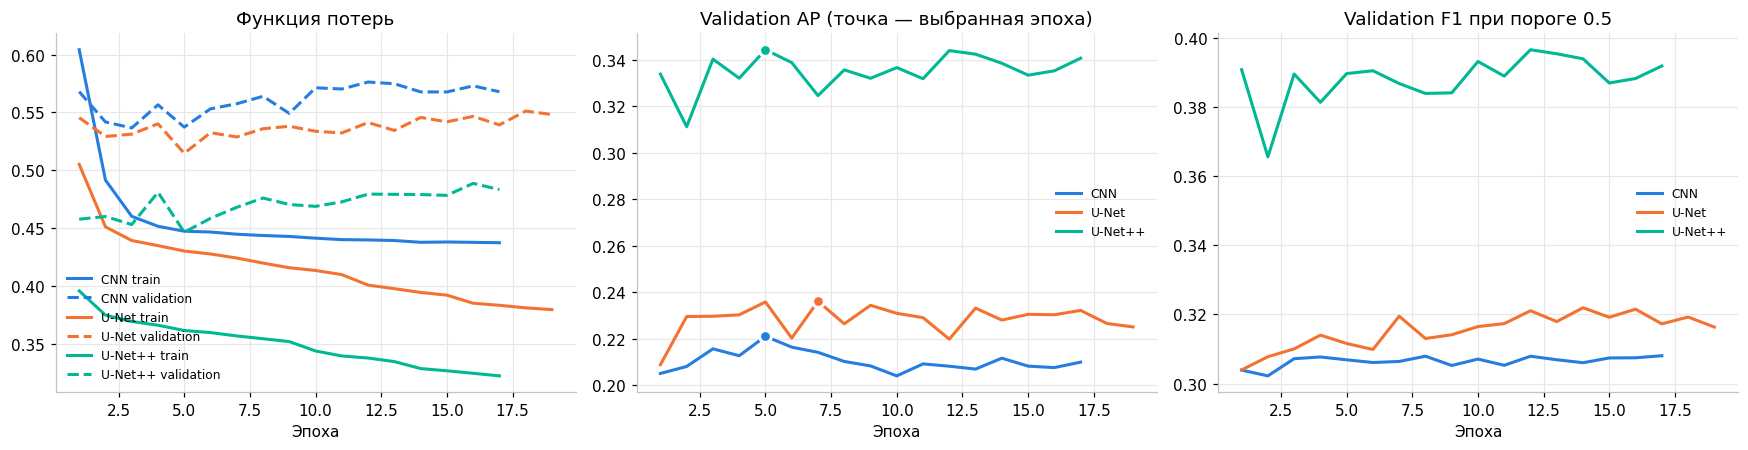

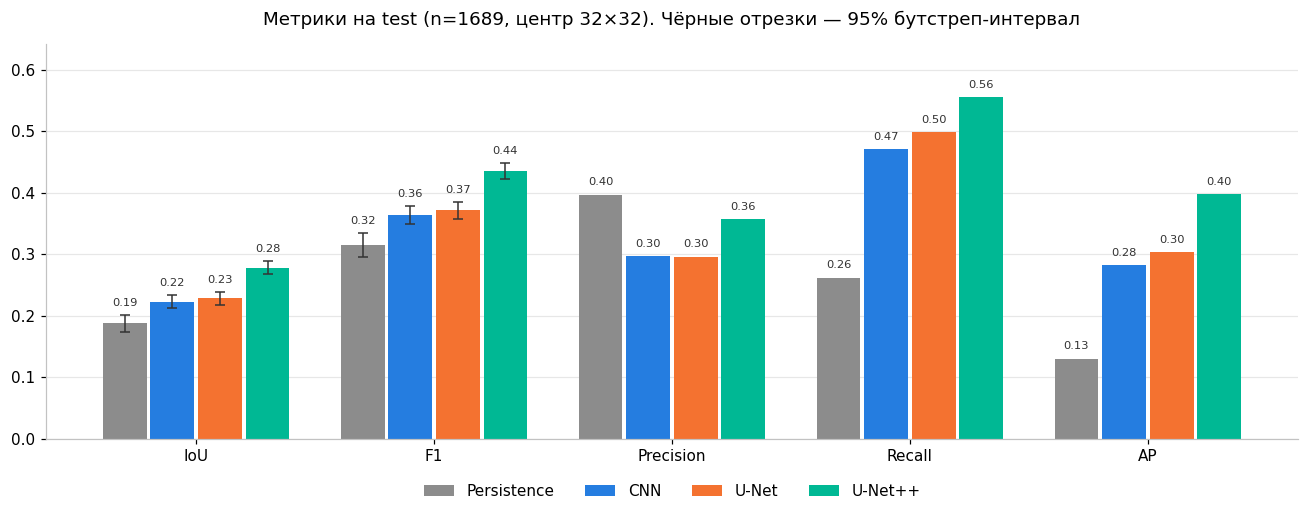

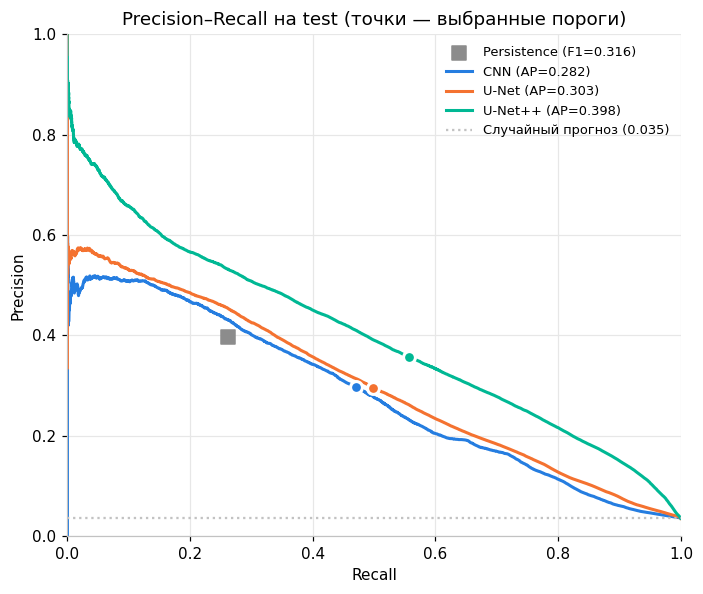

In [8]:
# 7.1 Кривые обучения
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for a in ARCHITECTURES:
    h = results[a]['history']; e = [r['epoch'] for r in h]; color = COLORS[NAMES[a]]
    axes[0].plot(e, [r['optimization_loss'] for r in h], color=color, lw=2, label=NAMES[a] + ' train')
    axes[0].plot(e, [r['validation']['loss'] for r in h], color=color, lw=2, ls='--', label=NAMES[a] + ' validation')
    axes[1].plot(e, [r['validation']['auc_pr'] for r in h], color=color, lw=2, label=NAMES[a])
    axes[1].scatter([results[a]['best_epoch']], [h[results[a]['best_epoch'] - 1]['validation']['auc_pr']],
                    color=color, s=60, zorder=3, edgecolor='white', linewidth=2)
    axes[2].plot(e, [r['validation']['f1'] for r in h], color=color, lw=2, label=NAMES[a])
for ax, title in zip(axes, ['Функция потерь', 'Validation AP (точка — выбранная эпоха)', 'Validation F1 при пороге 0.5']):
    ax.set_title(title); ax.set_xlabel('Эпоха'); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / '01_learning_curves.png'); plt.show()

# 7.2 Сравнение метрик на test
metric_keys = [('global_iou', 'IoU'), ('f1', 'F1'), ('precision', 'Precision'), ('recall', 'Recall'), ('auc_pr', 'AP')]
names_order = list(probabilities)
fig, ax = plt.subplots(figsize=(12, 4.8))
width = .8 / len(names_order)
for i, name in enumerate(names_order):
    xs = np.arange(len(metric_keys)) + (i - (len(names_order) - 1) / 2) * width
    values = [test_metrics[name][k] for k, _ in metric_keys]
    bars = ax.bar(xs, values, width * .92, color=COLORS[name], label=name, zorder=2)
    f1_b, iou_b = boot_values[name]
    for j, b in ((0, iou_b), (1, f1_b)):
        ax.errorbar(xs[j], values[j], yerr=[[values[j] - np.percentile(b, 2.5)], [np.percentile(b, 97.5) - values[j]]],
                    color='#333333', capsize=3, lw=1, zorder=3)
    tops = list(values)
    tops[0] = max(values[0], np.percentile(iou_b, 97.5)); tops[1] = max(values[1], np.percentile(f1_b, 97.5))
    for x, v, top in zip(xs, values, tops):
        ax.text(x, top + .012, f'{v:.2f}', ha='center', va='bottom', fontsize=7.5, color='#333333')
ax.set_xticks(np.arange(len(metric_keys))); ax.set_xticklabels([n for _, n in metric_keys])
ax.set_ylim(0, max(max(test_metrics[n][k] for k, _ in metric_keys) for n in names_order) * 1.12 + .02)
ax.set_title(f'Метрики на test (n={len(target)}, центр 32×32). Чёрные отрезки — 95% бутстреп-интервал', pad=12)
ax.legend(frameon=False, ncol=len(names_order), loc='upper center', bbox_to_anchor=(.5, -.08)); ax.grid(axis='x', visible=False)
fig.tight_layout(); fig.savefig(FIG / '02_test_metrics.png'); plt.show()

# 7.3 PR-кривые
fig, ax = plt.subplots(figsize=(6.5, 5.5))
v = valid >= .5
labels_flat = truth[v].astype(np.uint8)
for name, p in probabilities.items():
    m = test_metrics[name]
    if name == 'Persistence':
        ax.scatter(m['recall'], m['precision'], s=90, marker='s', color=COLORS[name], label=f'Persistence (F1={m["f1"]:.3f})', zorder=4)
        continue
    precision, recall, _ = precision_recall_curve(labels_flat, p[v])
    ax.plot(recall, precision, lw=2, color=COLORS[name], label=f'{name} (AP={m["auc_pr"]:.3f})')
    ax.scatter(m['recall'], m['precision'], s=60, color=COLORS[name], edgecolor='white', linewidth=2, zorder=4)
ax.axhline(labels_flat.mean(), color='#c2c2c2', ls=':', lw=1.5, label=f'Случайный прогноз ({labels_flat.mean():.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title('Precision–Recall на test (точки — выбранные пороги)')
ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG / '03_pr_curves.png'); plt.show()

Кандидатов для показа (≥20 пожарных клеток): 705 из 1689


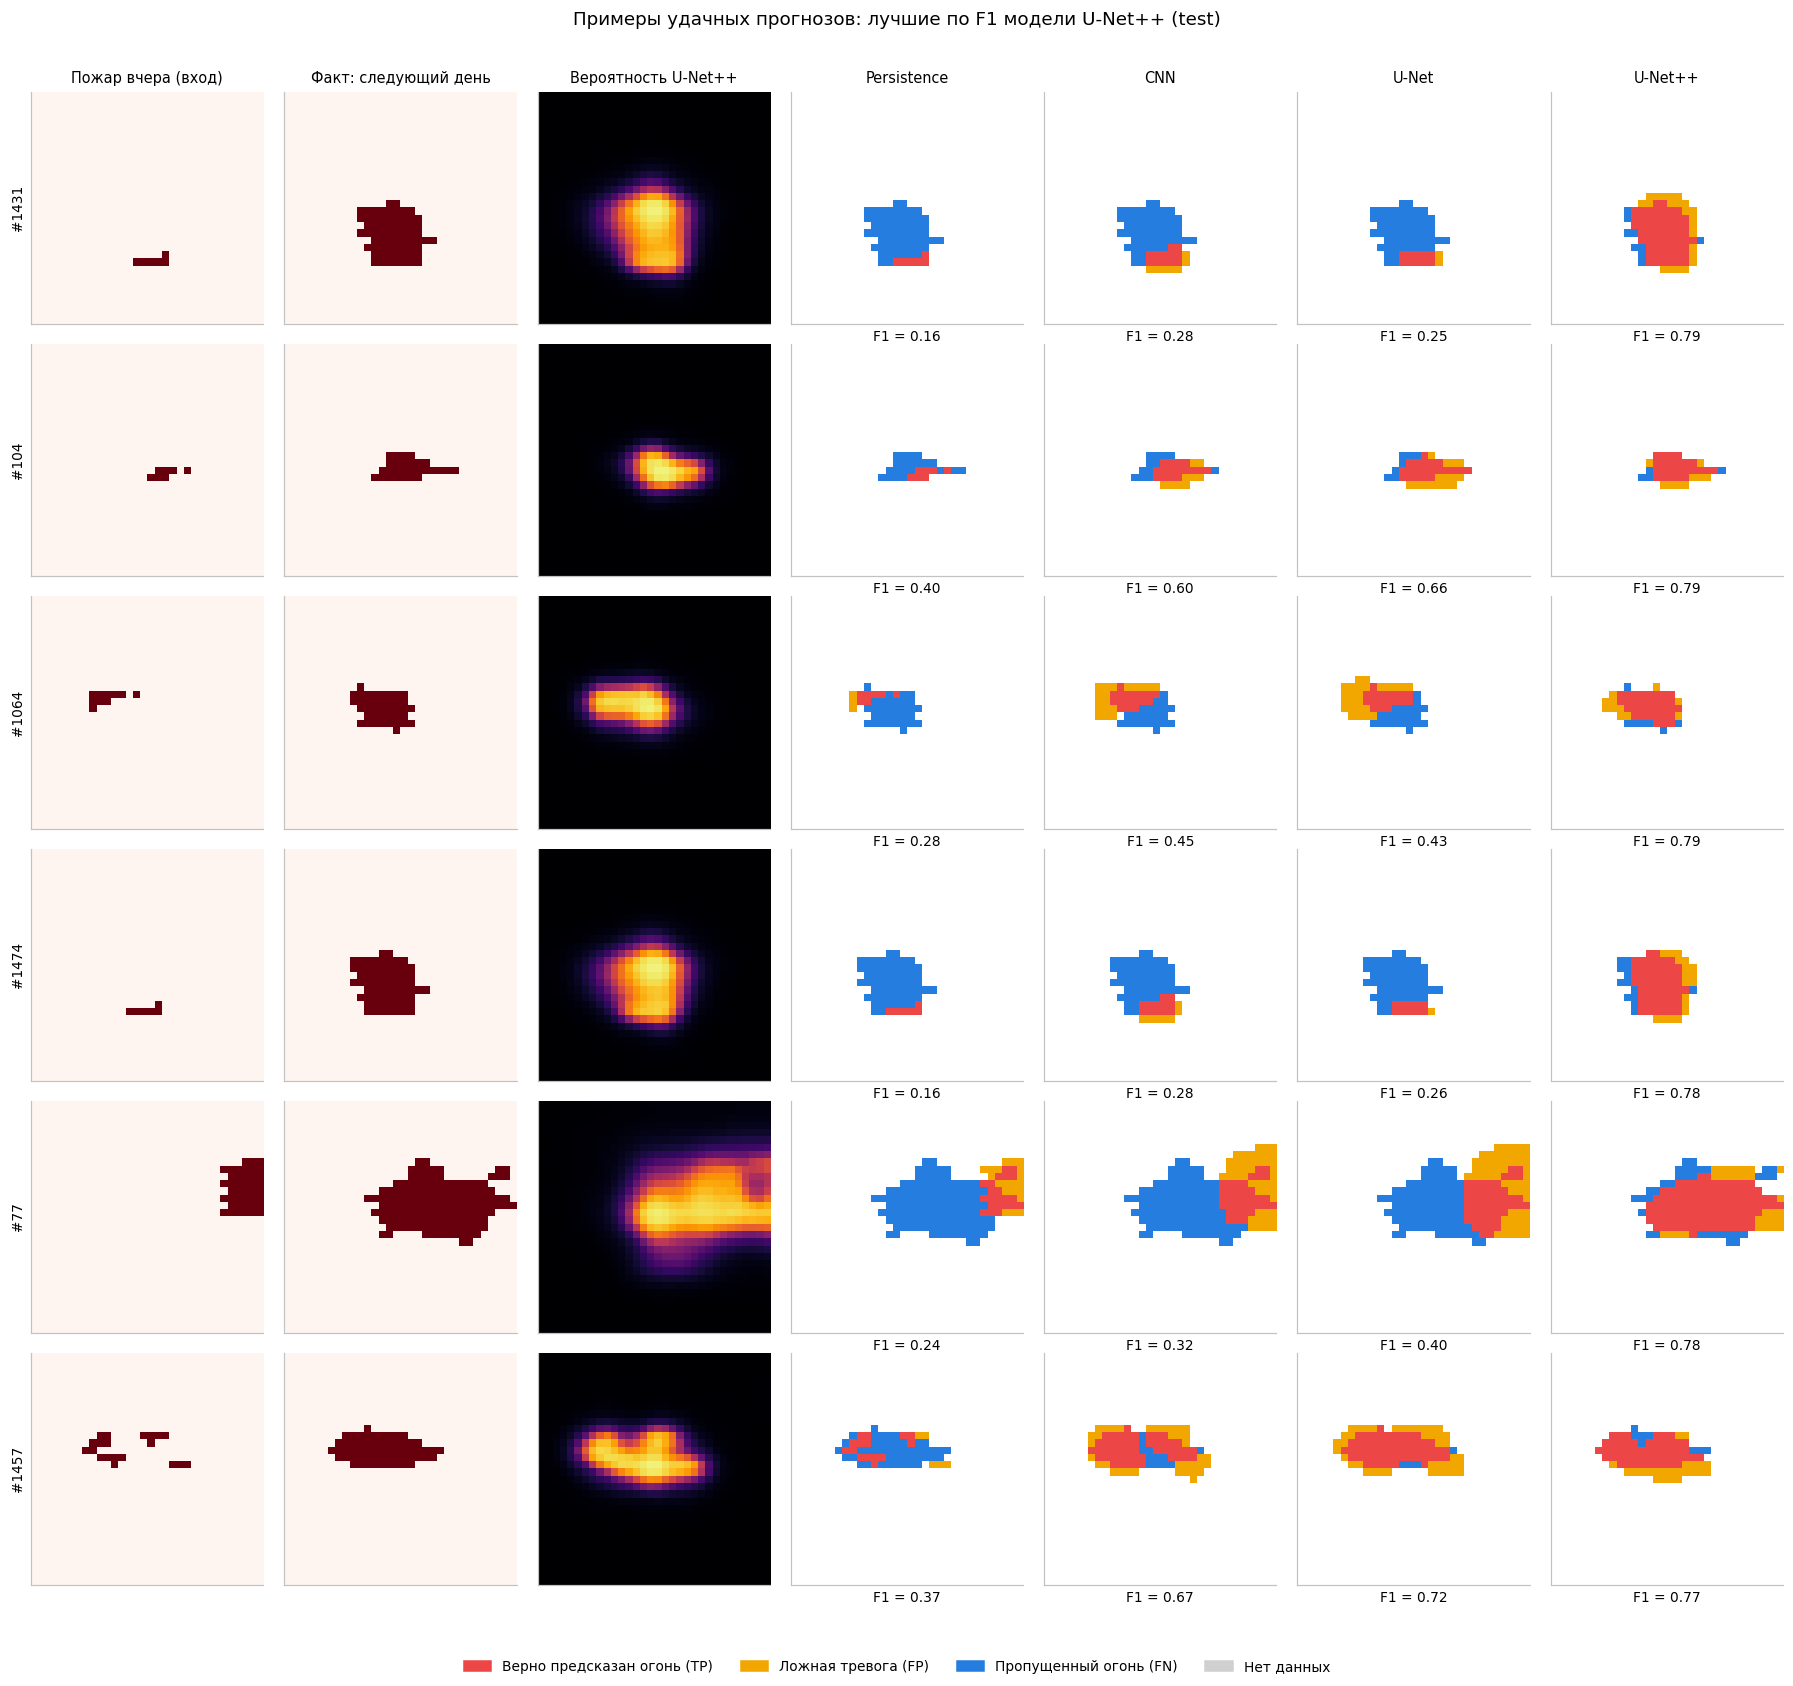

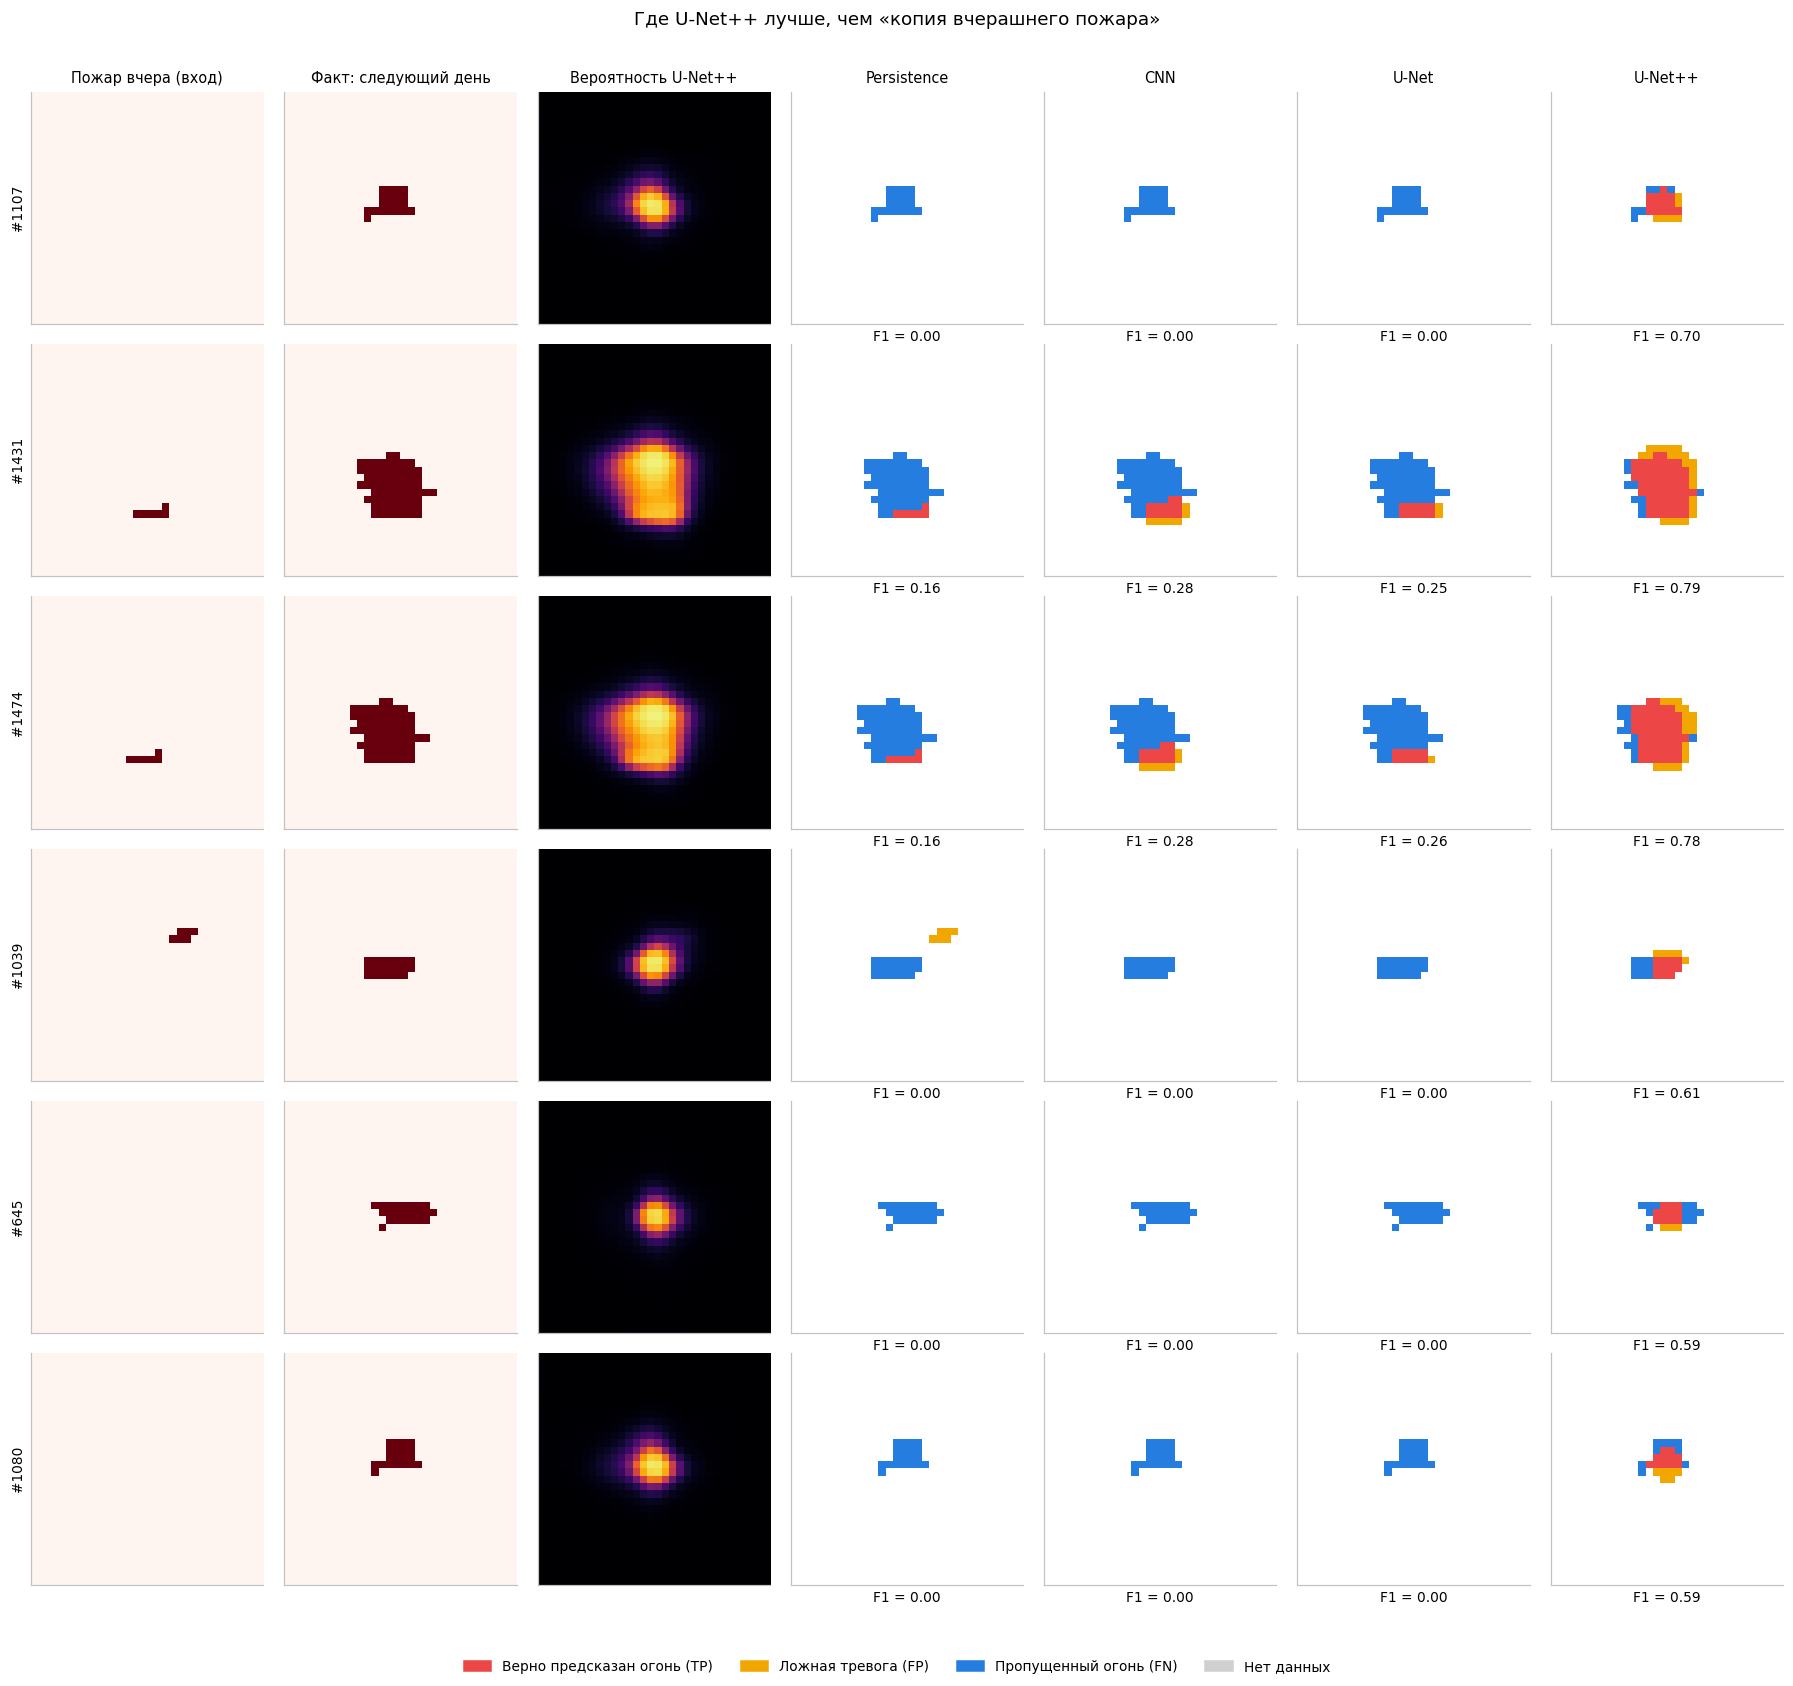

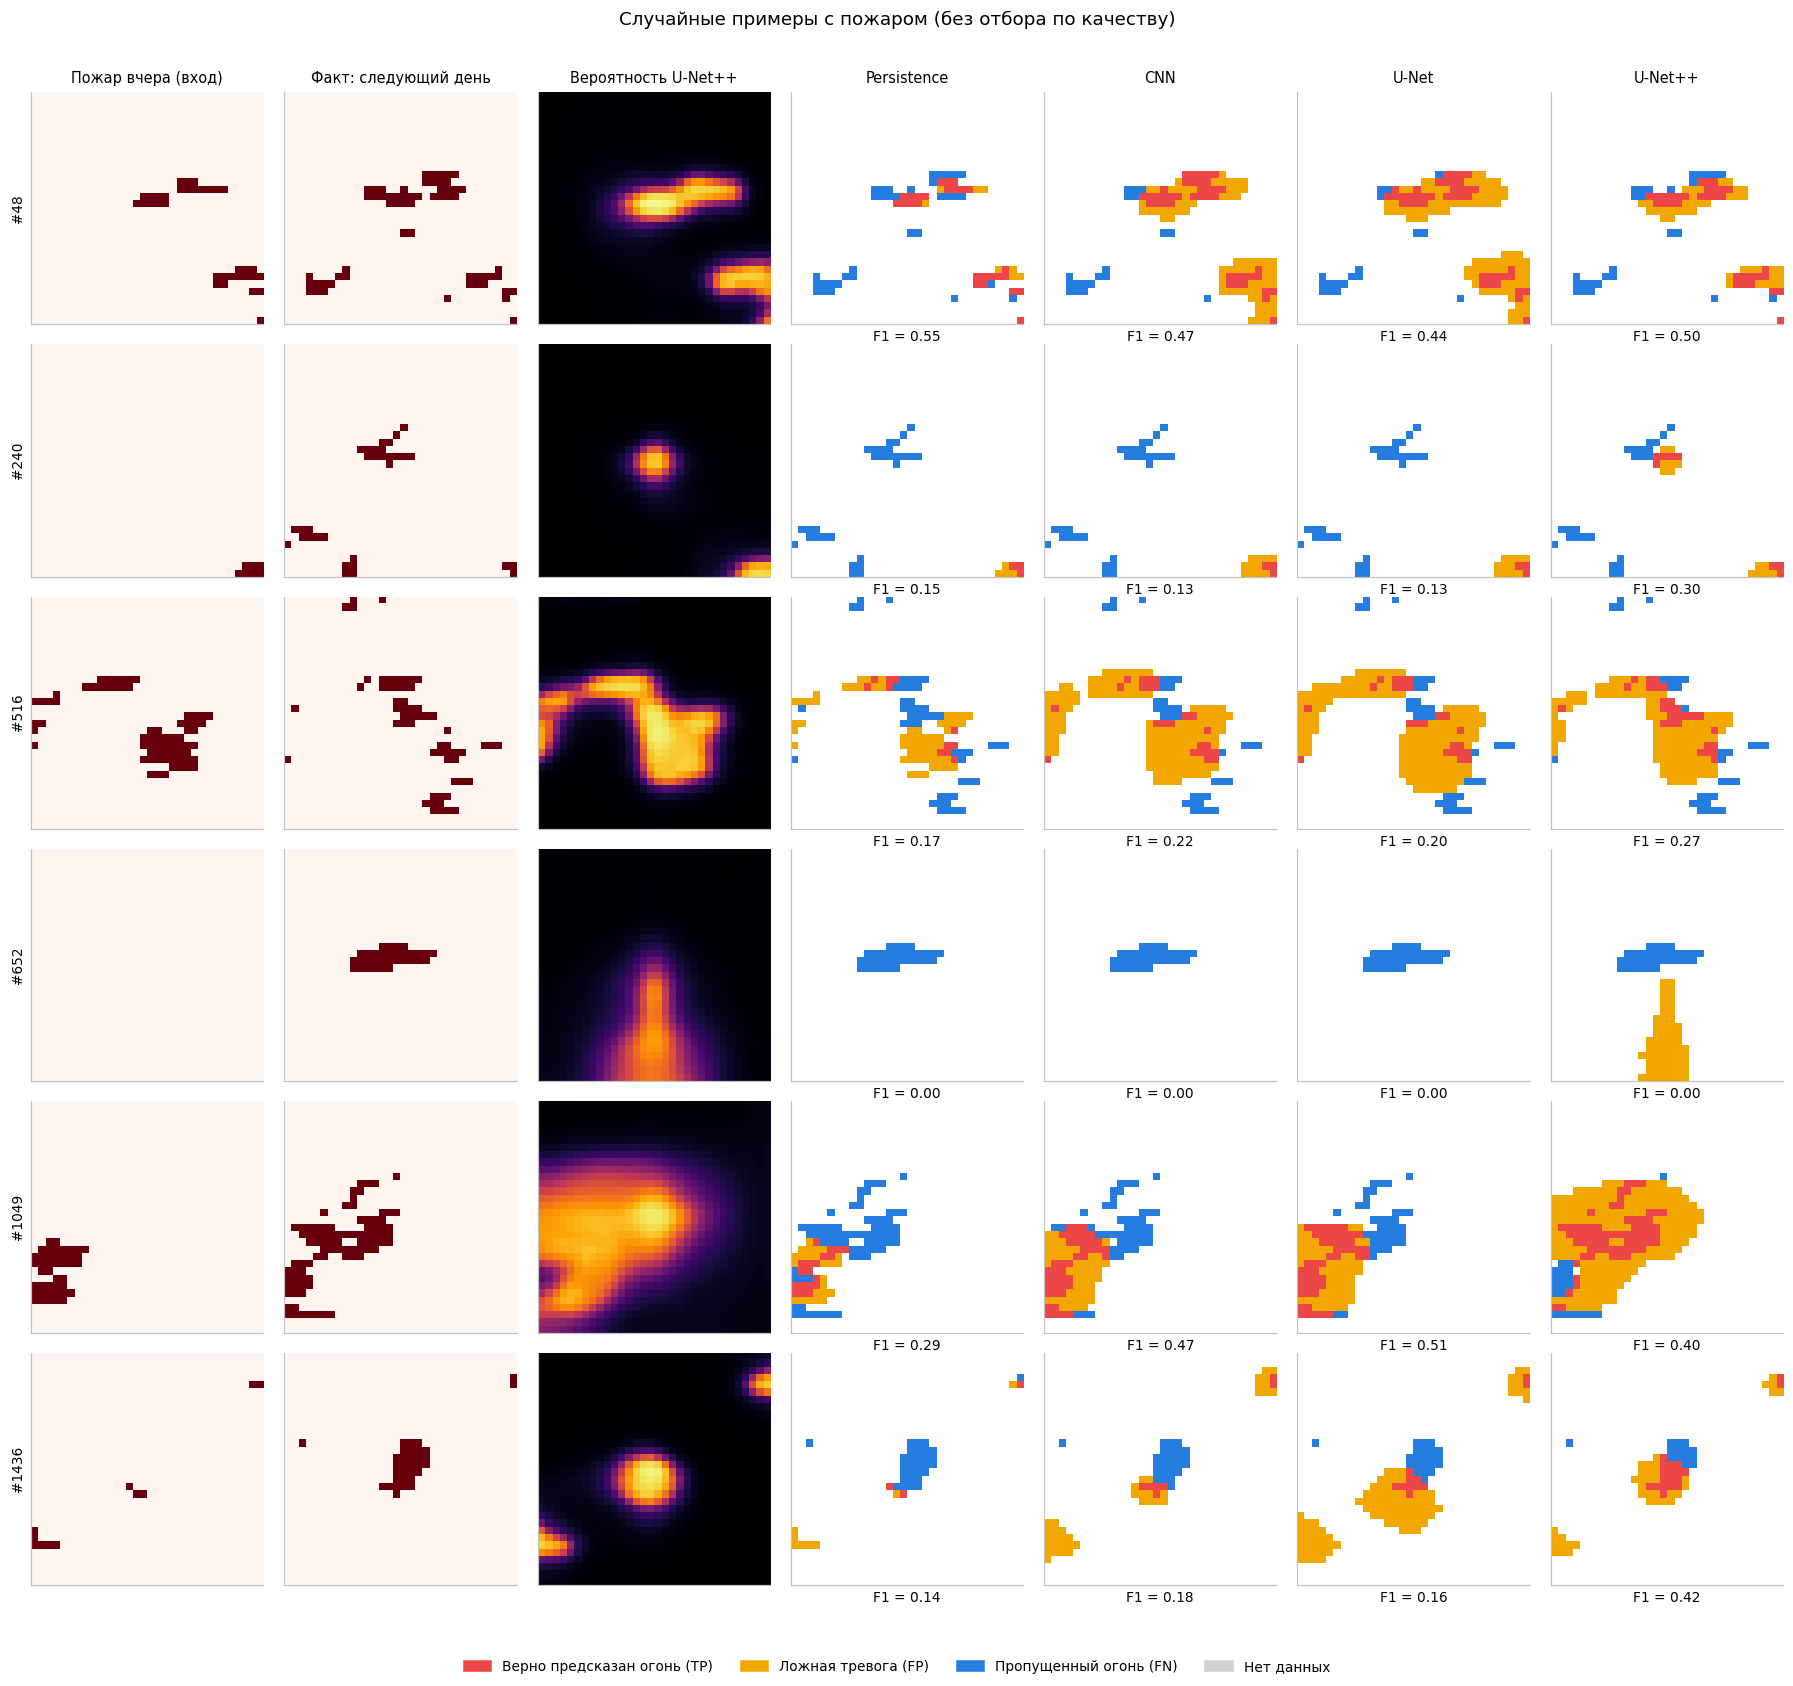

/tmp/ipykernel_413/1561117978.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(h_pad=2.5); fig.savefig(FIG / '07_input_channels.png'); plt.show()


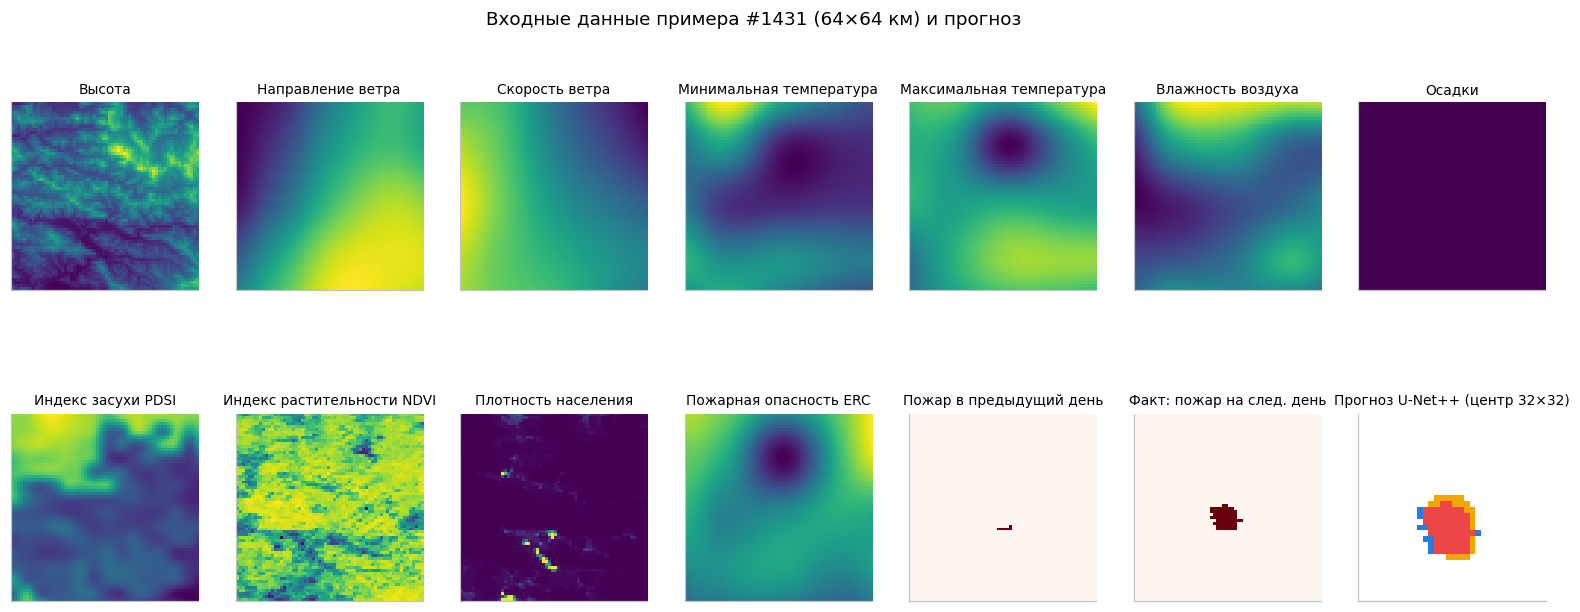

,Пример,Пожарных клеток,F1 Persistence,F1 CNN,F1 U-Net,F1 U-Net++
0,1431,67,0.164,0.279,0.253,0.789
1,104,28,0.400,0.604,0.656,0.787
2,1064,40,0.280,0.453,0.434,0.786
3,1474,67,0.164,0.279,0.256,0.777
4,77,143,0.238,0.321,0.402,0.776
5,1457,61,0.370,0.671,0.717,0.774


In [9]:
# 7.4 Примеры прогнозов
ERROR_COLORS = {'TP': '#ec4647', 'FP': '#f2a600', 'FN': '#257de0', 'unknown': '#d0d0d0'}
def error_map(p, threshold, index):
    pred = p[index, 0] >= threshold; tr = truth[index, 0]; unknown = valid[index, 0] < .5
    image = np.ones((*pred.shape, 3))
    for key, cells in (('TP', pred & tr), ('FP', pred & ~tr), ('FN', ~pred & tr), ('unknown', unknown)):
        image[cells & (~unknown if key != 'unknown' else True)] = matplotlib.colors.to_rgb(ERROR_COLORS[key])
    return image

def sample_f1(name):
    tp, fp, fn = counts[name]
    return np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 1.0)

f1_per_sample = {name: sample_f1(name) for name in probabilities}
fire_pixels = truth.sum((1, 2, 3))
candidates = np.where(fire_pixels >= MIN_FIRE_PIXELS)[0]
best_name = NAMES[BEST]
print(f'Кандидатов для показа (≥{MIN_FIRE_PIXELS} пожарных клеток): {len(candidates)} из {len(target)}')
fire_cmap = plt.get_cmap('Reds').copy(); fire_cmap.set_bad(ERROR_COLORS['unknown'])

def plot_examples(ids, title, filename):
    model_names = [NAMES[a] for a in ARCHITECTURES]
    columns = ['Пожар вчера (вход)', 'Факт: следующий день', f'Вероятность {best_name}', 'Persistence'] + model_names
    fig, axes = plt.subplots(len(ids), len(columns), figsize=(2.35 * len(columns), 2.45 * len(ids) + .8), squeeze=False)
    for r, i in enumerate(ids):
        axes[r, 0].imshow(persistence[i, 0], cmap='Reds', vmin=0, vmax=1, interpolation='nearest')
        axes[r, 1].imshow(np.ma.array(target[i, 0], mask=valid[i, 0] < .5), cmap=fire_cmap, vmin=0, vmax=1, interpolation='nearest')
        axes[r, 2].imshow(probabilities[best_name][i, 0], cmap='inferno', vmin=0, vmax=1, interpolation='nearest')
        for c, name in enumerate(['Persistence'] + model_names, start=3):
            axes[r, c].imshow(error_map(probabilities[name], thresholds[name], i), interpolation='nearest')
            axes[r, c].set_xlabel(f'F1 = {f1_per_sample[name][i]:.2f}', fontsize=9)
        axes[r, 0].set_ylabel(f'#{i}', fontsize=9)
        for c, ax in enumerate(axes[r]):
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            if r == 0: ax.set_title(columns[c], fontsize=9.5)
    handles = [Patch(color=ERROR_COLORS['TP'], label='Верно предсказан огонь (TP)'),
               Patch(color=ERROR_COLORS['FP'], label='Ложная тревога (FP)'),
               Patch(color=ERROR_COLORS['FN'], label='Пропущенный огонь (FN)'),
               Patch(color=ERROR_COLORS['unknown'], label='Нет данных')]
    fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, fontsize=9)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout(rect=(0, .04, 1, .97)); fig.savefig(FIG / filename); plt.show()

best_ids = candidates[np.argsort(-f1_per_sample[best_name][candidates])][:N_EXAMPLES]
plot_examples(best_ids, f'Примеры удачных прогнозов: лучшие по F1 модели {best_name} (test)', '04_best_examples.png')

gain = f1_per_sample[best_name] - f1_per_sample['Persistence']
gain_ids = candidates[np.argsort(-gain[candidates])][:N_EXAMPLES]
plot_examples(gain_ids, f'Где {best_name} лучше, чем «копия вчерашнего пожара»', '05_better_than_persistence.png')

random_ids = np.sort(np.random.default_rng(2026).choice(candidates, min(N_EXAMPLES, len(candidates)), replace=False))
plot_examples(random_ids, 'Случайные примеры с пожаром (без отбора по качеству)', '06_random_examples.png')

# 7.5 Все 12 входных каналов для лучшего примера
i = int(best_ids[0])
fig, axes = plt.subplots(2, 7, figsize=(18, 6.4), gridspec_kw={'hspace': .35})
for ax, (c, name) in zip(axes.flat, enumerate(ALL_FEATURES)):
    ax.imshow(test_x[i, c], cmap='Reds' if name == 'PrevFireMask' else 'viridis', interpolation='nearest')
    ax.set_title(FEATURE_LABELS[name], fontsize=9)
ax = axes.flat[12]
ax.imshow(np.ma.array(test_y[i, 0], mask=test_v[i, 0] < .5), cmap=fire_cmap, vmin=0, vmax=1, interpolation='nearest')
ax.set_title('Факт: пожар на след. день', fontsize=9)
axes.flat[13].imshow(error_map(probabilities[best_name], thresholds[best_name], i), interpolation='nearest')
axes.flat[13].set_title(f'Прогноз {best_name} (центр 32×32)', fontsize=9)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle(f'Входные данные примера #{i} (64×64 км) и прогноз', fontsize=12)
fig.tight_layout(h_pad=2.5); fig.savefig(FIG / '07_input_channels.png'); plt.show()

example_table = pd.DataFrame({'Пример': best_ids, 'Пожарных клеток': fire_pixels[best_ids],
                              **{f'F1 {n}': np.round(f1_per_sample[n][best_ids], 3) for n in probabilities}})
example_table.to_csv(OUTPUT / 'best_examples.csv', index=False, encoding='utf-8-sig')
display(example_table)

## 8. Вклад признаков (абляция)
Одна архитектура, одинаковые настройки, меняется только набор входных каналов. Набор «Все 12 признаков» берётся из основного обучения.

U-Net [Только вчерашний пожар] | эпоха 1/60:   0%|          | 0/937 [00:00<?, ?it/s]

U-Net [Только вчерашний пожар] | эпоха 01: train loss=0.5252  val loss=0.5490  val AP=0.1897  val F1@0.5=0.2971  lr=1.0e-04  ★ лучшая


U-Net [Только вчерашний пожар] | эпоха 2/60:   0%|          | 0/937 [00:00<?, ?it/s]

U-Net [Только вчерашний пожар] | эпоха 02: train loss=0.4600  val loss=0.5439  val AP=0.1917  val F1@0.5=0.2973  lr=1.0e-04  ★ лучшая


U-Net [Только вчерашний пожар] | эпоха 3/60:   0%|          | 0/937 [00:00<?, ?it/s]

U-Net [Только вчерашний пожар] | эпоха 03: train loss=0.4485  val loss=0.5426  val AP=0.1990  val F1@0.5=0.3029  lr=1.0e-04  ★ лучшая


... (181 outputs left out)

U-Net [Все, кроме ветра и PDSI] | эпоха 20: train loss=0.3775  val loss=0.5416  val AP=0.2413  val F1@0.5=0.3258  lr=2.5e-05


U-Net [Все, кроме ветра и PDSI] | эпоха 21/60:   0%|          | 0/937 [00:00<?, ?it/s]

U-Net [Все, кроме ветра и PDSI] | эпоха 21: train loss=0.3756  val loss=0.5334  val AP=0.2366  val F1@0.5=0.3230  lr=1.3e-05
U-Net [Все, кроме ветра и PDSI]: ранняя остановка — 12 эпох без роста validation AP
U-Net [Все, кроме ветра и PDSI]: лучшая эпоха 9, порог 0.42, validation F1=0.3286, AP=0.2535, время 7.7 мин


,Набор признаков,Каналов,Validation AP,Test IoU,Test F1,Test Precision,Test Recall,Test AP
0,Только вчерашний пожар,1,0.206600,0.2231,0.3649,0.2780,0.5309,0.2838
1,+ NDVI,2,0.233500,0.2295,0.3733,0.2996,0.4951,0.3096
2,+ NDVI + ERC,3,0.242400,0.2281,0.3715,0.2965,0.4973,0.2941
3,"Все, кроме ветра и PDSI",9,0.253500,0.2358,0.3816,0.3088,0.4995,0.3122
4,Все 12 признаков,12,0.236000,0.2284,0.3718,0.2963,0.4992,0.3030


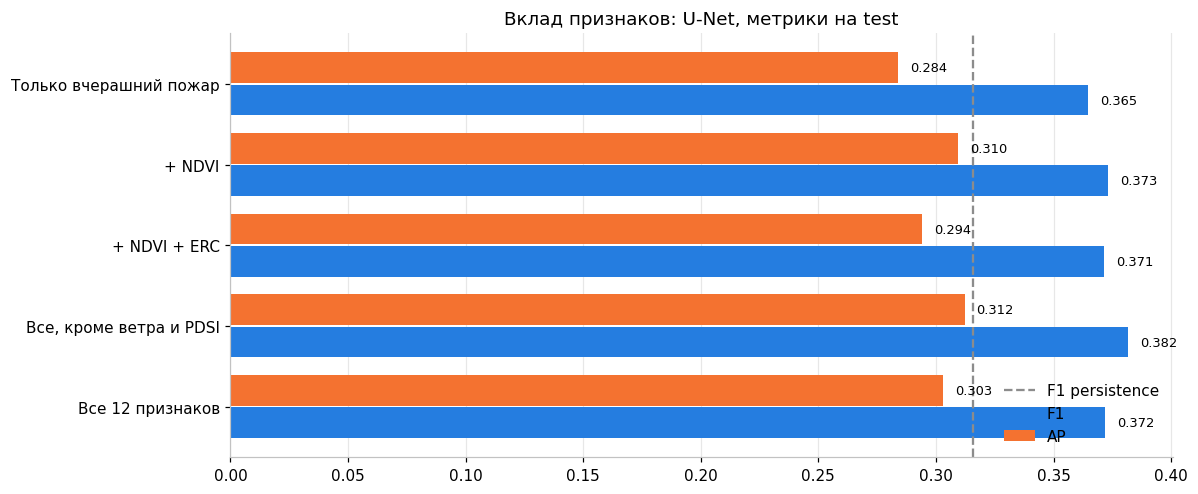

In [10]:
ablation_table = None
if RUN_ABLATION:
    rows = []
    for label, feature_names in ABLATION_SETS.items():
        channels = tuple(ALL_FEATURES.index(f) for f in feature_names)
        if channels == CH_ALL and ABLATION_ARCH in results:
            ckpt = results[ABLATION_ARCH]
        else:
            slug = '_'.join(feature_names) if len(feature_names) <= 4 else 'no_' + '_'.join(sorted(set(ALL_FEATURES) - set(feature_names)))
            ckpt = train_model(ABLATION_ARCH, channels, OUTPUT / 'ablation' / slug, f'{NAMES[ABLATION_ARCH]} [{label}]')
        model = load_model(ckpt)
        _, p, t, m = predict(model, make_loader('test', channels))
        metrics = tw.segmentation_metrics(p, t, m, ckpt['threshold'])
        rows.append({'Набор признаков': label, 'Каналов': len(channels),
                     'Validation AP': round(ckpt['validation']['auc_pr'], 4),
                     'Test IoU': metrics['global_iou'], 'Test F1': metrics['f1'],
                     'Test Precision': metrics['precision'], 'Test Recall': metrics['recall'], 'Test AP': metrics['auc_pr']})
        del model; free_memory()
    ablation_table = pd.DataFrame(rows)
    ablation_table.to_csv(OUTPUT / 'ablation.csv', index=False, encoding='utf-8-sig')
    display(ablation_table.style.format({k: '{:.4f}' for k in ['Test IoU', 'Test F1', 'Test Precision', 'Test Recall', 'Test AP']}))

    fig, ax = plt.subplots(figsize=(11, 4.6))
    y = np.arange(len(ablation_table))
    ax.barh(y + .2, ablation_table['Test F1'], .38, color='#257de0', label='F1', zorder=2)
    ax.barh(y - .2, ablation_table['Test AP'], .38, color='#f47230', label='AP', zorder=2)
    for yy, f1, ap in zip(y, ablation_table['Test F1'], ablation_table['Test AP']):
        ax.text(f1 + .005, yy + .2, f'{f1:.3f}', va='center', fontsize=8.5)
        ax.text(ap + .005, yy - .2, f'{ap:.3f}', va='center', fontsize=8.5)
    ax.axvline(test_metrics['Persistence']['f1'], color='#8c8c8c', ls='--', lw=1.5, label='F1 persistence')
    ax.set_yticks(y); ax.set_yticklabels(ablation_table['Набор признаков']); ax.invert_yaxis()
    ax.set_title(f'Вклад признаков: {NAMES[ABLATION_ARCH]}, метрики на test'); ax.legend(frameon=False, loc='lower right')
    ax.grid(axis='y', visible=False)
    fig.tight_layout(); fig.savefig(FIG / '08_feature_ablation.png'); plt.show()
else:
    print('Абляция выключена (RUN_ABLATION = False)')

## 9. Итоговый отчёт с числами

In [11]:
def md_table(df, float_format='{:.4g}'):
    cells = [[float_format.format(v) if isinstance(v, float) else str(v) for v in row] for row in df.values]
    head = '| ' + ' | '.join(map(str, df.columns)) + ' |\n|' + '---|' * len(df.columns) + '\n'
    return head + '\n'.join('| ' + ' | '.join(r) + ' |' for r in cells) + '\n'

best_m, pers_m = test_metrics[best_name], test_metrics['Persistence']
diff = boot_values[best_name][0] - boot_values['Persistence'][0]
win_share = float((diff > 0).mean())
lines = [
    '# Итоговые результаты: прогноз пожара на следующий день', '',
    '## Данные', md_table(data_table),
    '## Обучение', md_table(training_table),
    f'## Метрики на test (n={len(target)}, центр 32×32)', md_table(test_table), '',
    '## Выводы (числа подставлены автоматически)',
    f'- Лучшая модель, выбранная по validation AP без использования test: **{best_name}**.',
    f'- На test {best_name}: F1 = {best_m["f1"]:.3f}, IoU = {best_m["global_iou"]:.3f}, '
    f'Precision = {best_m["precision"]:.3f}, Recall = {best_m["recall"]:.3f}, AP = {best_m["auc_pr"]:.3f}.',
    f'- Persistence (копия вчерашнего пожара): F1 = {pers_m["f1"]:.3f}, IoU = {pers_m["global_iou"]:.3f}.',
    f'- Разница F1 {best_name} − persistence: {best_m["f1"] - pers_m["f1"]:+.3f} '
    f'(95% бутстреп-интервал {np.percentile(diff, 2.5):+.3f}…{np.percentile(diff, 97.5):+.3f}; '
    f'модель лучше в {win_share:.0%} бутстреп-выборок).',
    f'- Доля пожарных клеток в test: {truth.sum() / (valid >= .5).sum():.2%} — сильный дисбаланс классов; '
    f'AP случайного прогноза ≈ {truth.sum() / (valid >= .5).sum():.3f}.',
]
for a in ARCHITECTURES:
    c = results[a]
    params = f'{c["parameters"]:,}'.replace(',', ' ')
    lines.append(f'- {NAMES[a]}: {params} параметров, {c["train_time_sec"] / 60:.1f} мин обучения, '
                 f'test F1 = {test_metrics[NAMES[a]]["f1"]:.3f}, AP = {test_metrics[NAMES[a]]["auc_pr"]:.3f}.')
if ablation_table is not None:
    lines += ['', f'## Вклад признаков ({NAMES[ABLATION_ARCH]})', md_table(ablation_table)]
lines += ['', '## Протокол',
          '- Официальные train / eval / test не смешиваются, используются все записи.',
          '- Вход 64×64, loss и метрики — на центральных 32×32; неизвестные целевые клетки (−1) исключены.',
          '- Эпоха выбрана по validation AP, порог — по validation F1. Test использован один раз после обучения.',
          f'- Аугментация: {"повороты на 90° и отражения с пересчётом направления ветра" if AUGMENT else "нет"}. Один seed ({SEED}).',
          '- «Лучшие примеры» отобраны по test только для иллюстрации; метрики — по всему test.',
          '', '## Рисунки'] + [f'- figures/{p.name}' for p in sorted(FIG.glob('*.png'))]
summary = '\n'.join(lines)
(OUTPUT / 'results_summary.md').write_text(summary, encoding='utf-8')
display(Markdown(summary))

# Итоговые результаты: прогноз пожара на следующий день

## Данные
| Выборка | Примеров | Неизвестных целевых клеток | Доля пожарных клеток среди известных | Примеров с огнём в центре 32×32 |
|---|---|---|---|---|
| Train | 14979 | 2.09% | 3.18% | 12791 |
| Validation | 1877 | 2.18% | 3.83% | 1627 |
| Test | 1689 | 2.71% | 3.55% | 1434 |

## Обучение
| Модель | Параметров | Эпох обучено | Лучшая эпоха | Время обучения, мин | Порог (validation) | Validation F1 | Validation AP |
|---|---|---|---|---|---|---|---|
| CNN | 40 737 | 17 | 5 | 2.9 | 0.55 | 0.3095 | 0.221 |
| U-Net | 475 425 | 19 | 7 | 7.1 | 0.51 | 0.3198 | 0.236 |
| U-Net++ | 8 934 721 | 17 | 5 | 20.4 | 0.58 | 0.3924 | 0.3444 |

## Метрики на test (n=1689, центр 32×32)
| Модель | Порог | IoU | IoU 95% ДИ | F1 | F1 95% ДИ | Precision | Recall | AP | ΔF1 к persistence |
|---|---|---|---|---|---|---|---|---|---|
| Persistence | 0.5 | 0.1874 | 0.173–0.201 | 0.3156 | 0.295–0.334 | 0.3972 | 0.2618 | 0.1302 | — |
| CNN | 0.55 | 0.2227 | 0.212–0.234 | 0.3643 | 0.350–0.379 | 0.2971 | 0.4706 | 0.2822 | +0.049 [+0.040; +0.057] |
| U-Net | 0.51 | 0.2284 | 0.217–0.239 | 0.3718 | 0.357–0.385 | 0.2963 | 0.4992 | 0.303 | +0.056 [+0.046; +0.066] |
| U-Net++ | 0.58 | 0.2781 | 0.267–0.289 | 0.4352 | 0.422–0.448 | 0.3574 | 0.5563 | 0.3983 | +0.120 [+0.107; +0.133] |


## Выводы (числа подставлены автоматически)
- Лучшая модель, выбранная по validation AP без использования test: **U-Net++**.
- На test U-Net++: F1 = 0.435, IoU = 0.278, Precision = 0.357, Recall = 0.556, AP = 0.398.
- Persistence (копия вчерашнего пожара): F1 = 0.316, IoU = 0.187.
- Разница F1 U-Net++ − persistence: +0.120 (95% бутстреп-интервал +0.107…+0.133; модель лучше в 100% бутстреп-выборок).
- Доля пожарных клеток в test: 3.55% — сильный дисбаланс классов; AP случайного прогноза ≈ 0.035.
- CNN: 40 737 параметров, 2.9 мин обучения, test F1 = 0.364, AP = 0.282.
- U-Net: 475 425 параметров, 7.1 мин обучения, test F1 = 0.372, AP = 0.303.
- U-Net++: 8 934 721 параметров, 20.4 мин обучения, test F1 = 0.435, AP = 0.398.

## Вклад признаков (U-Net)
| Набор признаков | Каналов | Validation AP | Test IoU | Test F1 | Test Precision | Test Recall | Test AP |
|---|---|---|---|---|---|---|---|
| Только вчерашний пожар | 1 | 0.2066 | 0.2231 | 0.3649 | 0.278 | 0.5309 | 0.2838 |
| + NDVI | 2 | 0.2335 | 0.2295 | 0.3733 | 0.2996 | 0.4951 | 0.3096 |
| + NDVI + ERC | 3 | 0.2424 | 0.2281 | 0.3715 | 0.2965 | 0.4973 | 0.2941 |
| Все, кроме ветра и PDSI | 9 | 0.2535 | 0.2358 | 0.3816 | 0.3088 | 0.4995 | 0.3122 |
| Все 12 признаков | 12 | 0.236 | 0.2284 | 0.3718 | 0.2963 | 0.4992 | 0.303 |


## Протокол
- Официальные train / eval / test не смешиваются, используются все записи.
- Вход 64×64, loss и метрики — на центральных 32×32; неизвестные целевые клетки (−1) исключены.
- Эпоха выбрана по validation AP, порог — по validation F1. Test использован один раз после обучения.
- Аугментация: повороты на 90° и отражения с пересчётом направления ветра. Один seed (42).
- «Лучшие примеры» отобраны по test только для иллюстрации; метрики — по всему test.

## Рисунки
- figures/01_learning_curves.png
- figures/02_test_metrics.png
- figures/03_pr_curves.png
- figures/04_best_examples.png
- figures/05_better_than_persistence.png
- figures/06_random_examples.png
- figures/07_input_channels.png
- figures/08_feature_ablation.png

## 10. Скачать результаты
Архив: веса, таблицы CSV, `results_summary.md`, графики и истории обучения.

In [12]:
archive = shutil.make_archive(str(BASE / (RUN_NAME + '_results')), 'zip', OUTPUT)
print('Архив:', archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    pass

Архив: /content/wildfire_final/final_full_data_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Порог (1-й процентиль контроля): 0.0189
Test-примеров с почти-копией места в train: 349 из 1689 (20.7%)
Квантили расстояния test→train: [0.0035 0.0225 0.0398 0.0563]
Квантили контроля:             [0.0231 0.0401 0.0585 0.0726]


,Подвыборка,Примеров,F1 Persistence,AP Persistence,F1 CNN,AP CNN,F1 U-Net,AP U-Net,F1 U-Net++,AP U-Net++
0,Весь test,1689,0.3156,0.1302,0.3643,0.2822,0.3718,0.3030,0.4352,0.3983
1,Есть копия места в train,349,0.3120,0.1047,0.3619,0.2707,0.3568,0.3005,0.3102,0.2979
2,Нет копии в train,1340,0.3158,0.1354,0.3644,0.2849,0.3727,0.3048,0.4450,0.4097


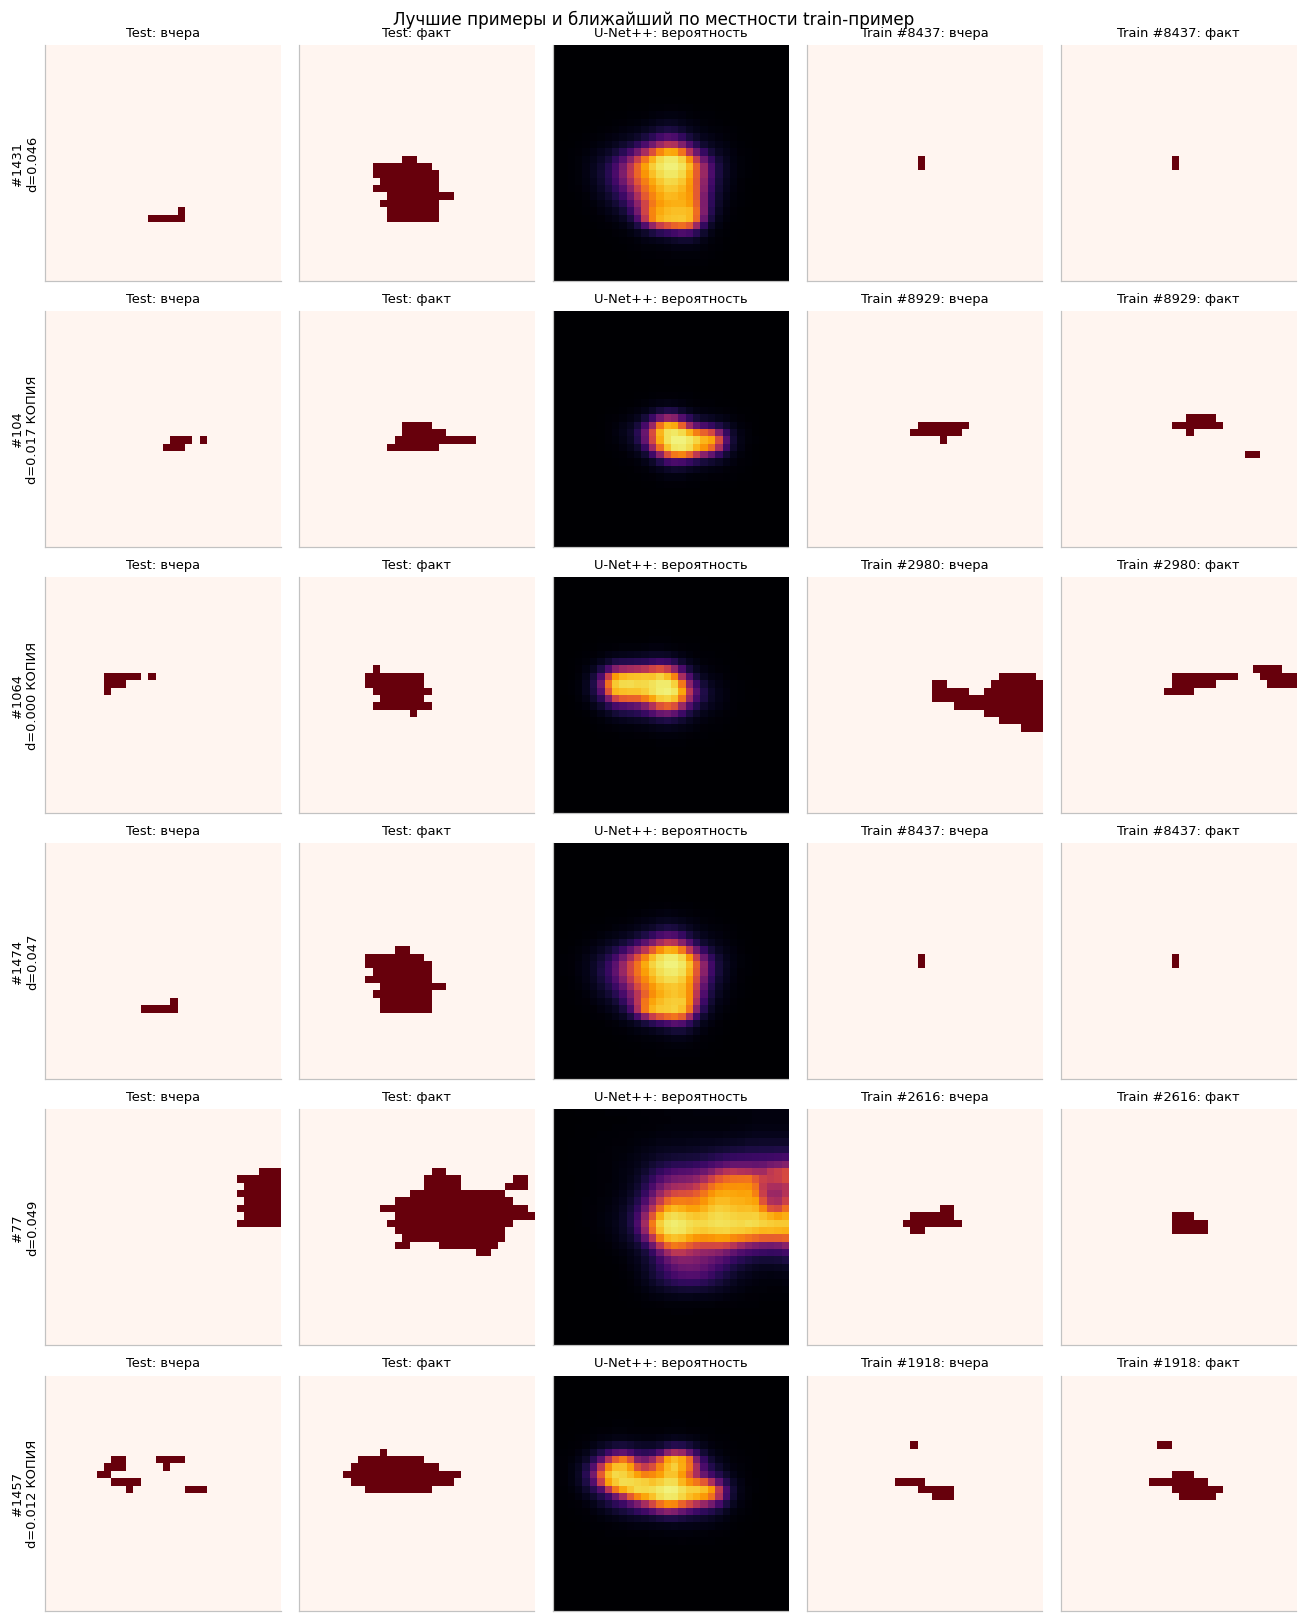

In [13]:
# ===== Проверка: есть ли в train почти копии тех же мест, что в test =====
import torch.nn.functional as F
STATIC = ['elevation', 'NDVI', 'population']        # признаки, почти не меняющиеся за пару дней
static_idx = [ALL_FEATURES.index(f) for f in STATIC]

def descriptors(x, flip=False):
    out = []
    for s in range(0, len(x), 512):
        t = torch.from_numpy(x[s:s + 512, static_idx]).to(DEVICE)
        t = F.avg_pool2d(t, 4)                       # 16×16 клеток по 4 км: терпит небольшие сдвиги
        out.append((t.flip(-1) if flip else t).flatten(1))
    return torch.cat(out)

def nearest(query, reference):
    dist, arg = [], []
    for s in range(0, len(query), 256):
        d = torch.cdist(query[s:s + 256], reference) / reference.shape[1] ** .5   # RMS-разница
        m, a = d.min(1); dist.append(m.cpu()); arg.append(a.cpu())
    return torch.cat(dist).numpy(), torch.cat(arg).numpy()

d_train = descriptors(splits['train'][0])
d_test = descriptors(splits['test'][0])
dist_test, nn_test = nearest(d_test, d_train)
# Контроль: отражённый train — настоящих копий там нет, это «случайное» сходство
dist_ctrl, _ = nearest(d_test, descriptors(splits['train'][0], flip=True))
THR = float(np.percentile(dist_ctrl, 1))
dup = dist_test < THR
print(f'Порог (1-й процентиль контроля): {THR:.4f}')
print(f'Test-примеров с почти-копией места в train: {dup.sum()} из {len(dup)} ({dup.mean():.1%})')
print('Квантили расстояния test→train:', np.round(np.percentile(dist_test, [5, 25, 50, 75]), 4))
print('Квантили контроля:            ', np.round(np.percentile(dist_ctrl, [5, 25, 50, 75]), 4))

rows = []
for subset, mask in [('Весь test', np.ones_like(dup)), ('Есть копия места в train', dup), ('Нет копии в train', ~dup)]:
    if mask.sum() == 0 or truth[mask].sum() == 0:
        continue
    row = {'Подвыборка': subset, 'Примеров': int(mask.sum())}
    for name, p in probabilities.items():
        m = tw.segmentation_metrics(p[mask], target[mask], valid[mask], thresholds[name])
        row[f'F1 {name}'] = round(m['f1'], 4); row[f'AP {name}'] = round(m['auc_pr'], 4)
    rows.append(row)
leak_table = pd.DataFrame(rows)
leak_table.to_csv(OUTPUT / 'duplicate_check.csv', index=False, encoding='utf-8-sig')
display(leak_table)

# Показанные «лучшие примеры» рядом с ближайшим train-примером
best_name = NAMES[BEST]
fig, axes = plt.subplots(len(best_ids), 5, figsize=(12, 2.5 * len(best_ids)), squeeze=False)
tx, ty = splits['train'][0], splits['train'][1]
for r, i in enumerate(best_ids):
    j = nn_test[i]
    panels = [(persistence[i, 0], 'Test: вчера'), (target[i, 0], 'Test: факт'),
              (probabilities[best_name][i, 0], f'{best_name}: вероятность'),
              (tw.center_crop(tx[j:j + 1, PREV:PREV + 1])[0, 0], f'Train #{j}: вчера'),
              (tw.center_crop(ty[j:j + 1])[0, 0], f'Train #{j}: факт')]
    for c, (img, title) in enumerate(panels):
        axes[r, c].imshow(img, cmap='inferno' if c == 2 else 'Reds', vmin=0, vmax=1, interpolation='nearest')
        axes[r, c].set_title(title, fontsize=8.5); axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
    axes[r, 0].set_ylabel(f'#{i}\nd={dist_test[i]:.3f}' + (' КОПИЯ' if dup[i] else ''), fontsize=8.5)
fig.suptitle('Лучшие примеры и ближайший по местности train-пример', fontsize=11)
fig.tight_layout(); fig.savefig(FIG / '09_duplicate_check.png'); plt.show()

In [14]:
# ===== Экспорт моделей и результатов для Streamlit =====
from wildfire_model import save_wildfire_checkpoint, load_wildfire_checkpoint

EXPORT = OUTPUT / 'streamlit_export'
(EXPORT / 'models').mkdir(parents=True, exist_ok=True)

for a in ARCHITECTURES:
    c = results[a]
    model = build_model(a, len(c['channels']))
    model.load_state_dict(c['model_state_dict'])
    path = save_wildfire_checkpoint(
        EXPORT / 'models' / f'{a}.pth', model, c['channels'],
        threshold=c['threshold'], input_size=64, output_size=32,
        metrics={'validation': c['validation'], 'test': test_metrics[NAMES[a]]},
    )
    load_wildfire_checkpoint(path)          # проверка: файл открывается так же, как в приложении
    print('OK:', path.name, 'порог', c['threshold'])

for name in ['test_comparison.csv', 'ablation.csv', 'data_summary.csv', 'training_summary.csv',
             'duplicate_check.csv', 'results_summary.md']:
    if (OUTPUT / name).exists():
        shutil.copy(OUTPUT / name, EXPORT / name)
shutil.copytree(FIG, EXPORT / 'figures', dirs_exist_ok=True)

# Примеры из test для демонстрации: нормализованные входы 64×64, факт и группа
groups = {}
for group, ids_ in [('random', random_ids), ('gain', gain_ids), ('best', best_ids)]:
    for i in ids_:
        groups[int(i)] = group               # если пример в нескольких группах — остаётся «best»
demo_ids = np.array(sorted(groups))
np.savez_compressed(EXPORT / 'demo_samples.npz', x=test_x[demo_ids], y=test_y[demo_ids],
                    valid=test_v[demo_ids], ids=demo_ids, group=np.array([groups[i] for i in demo_ids]))
print('Примеров для демонстрации:', len(demo_ids))

archive = shutil.make_archive(str(BASE / 'streamlit_export'), 'zip', EXPORT)
print('Архив:', archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    pass

OK: cnn.pth порог 0.55
OK: unet.pth порог 0.51
OK: unetpp.pth порог 0.58
Примеров для демонстрации: 16
Архив: /content/wildfire_final/streamlit_export.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>